<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ [Holomine] Paddy Field Segmentation Finals: Segmentasi Sawah dengan DINOv3 SAT-493M ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Segmentasi semantik biner lahan sawah dari citra Pleiades 1024x1024 di Sepatan Timur, Tangerang</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **PaddySeg**

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Nama Tim

- IndomaretLabtekV

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Prapemrosesan dan Augmentasi**](#4)
5. [**Validasi Spasial dan DataLoader**](#5)
6. [**Pemodelan**](#6)
7. [**Inferensi dan Submisi**](#7)
8. [**Pasca-Analisis**](#8)
9. [**Daftar Pustaka**](#9)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Lahan sawah di Sepatan Timur, Tangerang, berupa petak kecil yang terfragmentasi dan bercampur dengan pematang, saluran irigasi, jalan, serta permukiman. Masker sawah yang akurat mendukung estimasi luas tanam dan pemantauan alih fungsi lahan, dua kebutuhan nyata dalam perencanaan ketahanan pangan daerah. Pada babak final **[Holomine] Paddy Field Segmentation**, peserta diminta memprediksi masker sawah per piksel dari tile RGB turunan Pleiades.

- **Tugas**: segmentasi semantik biner, sawah vs latar
- **Masukan**: tile RGB 1024x1024, koordinat disamarkan
- **Keluaran**: masker resolusi penuh dalam format RLE gaya Airbus (column-major, berbasis 1)
- **Platform pelatihan**: vast.ai, GPU RTX 5090 (32 GB)

---

## Dataset

*Dataset* berisi 123 tile latih beserta masker biner (0 latar, 255 sawah) dan 129 tile uji (71 publik, 58 privat, pembagian disembunyikan). Tile train, uji-publik, dan uji-privat berasal dari blok yang terpisah secara spasial pada sumbu X dengan tile penyangga dibuang, sehingga model dinilai pada wilayah yang tidak pernah dilihat saat pelatihan.

```
data/
├── train/
|    ├── images/   train_000.png ... train_122.png
|    └── masks/    train_000.png ... train_122.png
├── test_images/   test_000.png ... test_128.png
└── sample_submission.csv
```

---

## Metrik

***Micro-IoU** kelas sawah menjumlahkan TP, FP, dan FN atas semua citra dalam satu split, lalu menghitung rasio.*

$$\text{IoU} = \frac{\sum TP}{\sum TP + \sum FP + \sum FN}$$

---

## Pendekatan: DINOv3 SAT-493M + *Decoder* Multi-Level + Validasi Spasial

DINOv3 ViT-L/16 SAT-493M adalah *foundation model* hasil pelatihan *self-supervised* Meta AI pada 493 juta citra satelit resolusi sangat tinggi (Simeoni dkk., 2025), sehingga fiturnya sudah memahami tekstur petak, pematang, dan permukiman pada citra sekelas Pleiades. EDA menunjukkan bahwa label sawah berupa poligon digitasi kasar dan kesalahan model berupa blok sepetak utuh, bukan batas piksel, sehingga kapasitas semantik dan konteks 768 sampai 1024 piksel lebih penting daripada detail tepi.

```
RGB tile (crop acak 768 saat train, tile penuh 1024 saat inferensi)
    |
    +-- DINOv3 ViT-L/16 SAT-493M (24 blok, RoPE, 4 register token, LLRD 0.9)
    |      hidden states blok 6 / 12 / 18 / 24 -> token grid H/16
    |      reassemble ala DPT -> stride 4 / 8 / 16 / 32 [256 ch]
    |
    +-- FPN top-down fusion -> stride 4 [256 ch]
    +-- RGB stem dangkal stride 4 [64 ch] (concat)
         |
    Conv head -> logit stride 4 -> bilinear x4 -> masker 1024x1024
```

Validasi memakai 5 *fold* spasial hasil rekonstruksi tata letak tile. Tile dipotong dengan *stride* 512 (overlap 50%), sehingga setiap tile yang berbagi piksel dengan tile validasi dibuang dari *training* fold tersebut (*purge*). Submisi akhir adalah *ensemble* dua resep (run 1 dan v3) yang dipilih berdasarkan validasi, bukan berdasarkan *leaderboard* publik.

---

## Referensi Utama

- `eda/01` sampai `eda/18`: seluruh skrip EDA, masing-masing menghasilkan angka dan gambar di `outputs/eda/`
- `handoff/`: catatan keputusan, riwayat submisi, dan pelajaran dari setiap iterasi

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

In [1]:
!nvidia-smi

Thu Oct  1 07:34:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        On  |   00000000:01:00.0 Off |                  N/A |
| 34%   47C    P8             11W /  500W |       1MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

> Catatan untuk juri dan panitia: untuk mereproduksi submisi tanpa *training* ulang, tetapkan `Settings.RUN_NAME = 'INFERENCE'` lalu jalankan *Run All*. Model DINOv3 di Hugging Face bersifat *gated*: setujui lisensinya di halaman model dan isi variabel lingkungan `HF_TOKEN`. Waktu tercatat di RTX 5090: sekitar 7 menit *training* ditambah 1 sampai 2 menit inferensi TTA per *fold*.

---

## Instalasi

Baris berikut memasang seluruh pustaka yang diperlukan. Pustaka *transformers* versi 4.56 ke atas dibutuhkan karena arsitektur DINOv3 baru tersedia mulai versi tersebut.

In [2]:
%pip install -q -U "transformers>=4.56" segmentation-models-pytorch timm opencv-python-headless scipy pandas matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


---

## Pustaka

Seluruh impor dikelompokkan dalam satu sel. PyTorch menjadi *framework* utama, *transformers* menyediakan *backbone* DINOv3, OpenCV menangani operasi citra dan *connected component*, sedangkan *segmentation-models-pytorch* menyediakan *fallback* UNet bila token Hugging Face tidak tersedia.

In [3]:
import os
import re
import gc
import math
import time
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

cv2.setNumThreads(0)
print(torch.__version__, torch.cuda.is_available())

2.11.0+cu128 True


---

## Seed

Pengaturan *seed* dilakukan pada semua sumber keacakan. Setiap *crop* training memakai generator acak sendiri, sehingga hasil antar eksekusi tetap dapat sedikit berbeda akibat penjadwalan *worker* dan operasi GPU.

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(2026)

---

## Settings

Kelas `Settings` memusatkan seluruh konfigurasi: jalur data, *hyperparameter*, probabilitas augmentasi, dan threshold submisi. Resep v3 memakai *crop* 768, 30 *epoch*, augmentasi radiometrik hasil EDA, dan *sampling* tile seimbang. `ENSEMBLE_WITH` menunjuk probabilitas test dari run 1 (resep sama, *seed* dan augmentasi lama) untuk *ensemble* akhir.

In [5]:
class Settings:
    SEED        = 2026
    RUN_NAME    = 'TRAIN'
    DRY_RUN     = False

    DATA_DIR    = Path('data') if Path('data/train').exists() else Path('../data')
    OUTPUT_DIR  = Path('outputs/dinov3_sat_v3')
    DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'

    BACKBONE    = 'dinov3_sat'
    HF_MODEL    = 'facebook/dinov3-vitl16-pretrain-sat493m'
    HF_TOKEN    = os.environ.get('HF_TOKEN')
    FEAT_LAYERS = (5, 11, 17, 23)
    SMP_ENCODER = 'tu-convnext_base'

    CROP        = 768
    BATCH       = 4
    EPOCHS      = 30
    STEPS_EPOCH = 60
    LR_DEC      = 3e-4
    LR_ENC      = 4e-5
    LLRD        = 0.9
    WD          = 0.05
    WARMUP      = 0.06
    EVAL_EVERY  = 5
    NUM_WORKERS = 8

    FOLDS       = [0, 1, 2, 3, 4]
    FULL_FIT    = False
    FULL_SEEDS  = (42,)
    TTA         = 8
    NODATA_AREA = 4096
    SUB_THR     = 0.10
    EXTRA_THRS  = (0.10, 0.15)
    USE_OVERLAP = False
    RUN1_PROBS  = [Path('outputs/dinov3_sat/test_prob_mean.npy'), Path('results/paddy_dinov3/test_prob_mean.npy')]
    ENSEMBLE_WITH = [next((p for p in RUN1_PROBS if p.exists()), RUN1_PROBS[0])]

    P_CONTRAST  = 0.5
    P_SEAM      = 0.2
    P_HAZE      = 0.25
    P_CLOUD     = 0.15
    P_BLUR      = 0.0
    P_ROTATE    = 0.3
    BALANCED    = True

CFG = Settings()
if CFG.DRY_RUN:
    CFG.EPOCHS, CFG.STEPS_EPOCH, CFG.FOLDS, CFG.EVAL_EVERY, CFG.TTA, CFG.CROP, CFG.BATCH = 1, 2, [0], 1, 2, 256, 2
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(CFG.DATA_DIR.resolve(), CFG.DEVICE, CFG.BACKBONE)

/workspace/data cuda dinov3_sat


---

## Muat Dataset

Semua tile dimuat sekali ke RAM sebagai uint8 (sekitar 750 MB untuk train dan test) agar *crop* acak dapat diambil tanpa membaca ulang disk.

In [6]:
def read_rgb(p):
    return cv2.cvtColor(cv2.imread(str(p), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)

train_files = sorted((CFG.DATA_DIR / 'train' / 'images').glob('*.png'))
mask_files  = sorted((CFG.DATA_DIR / 'train' / 'masks').glob('*.png'))
sub_tmpl    = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv')
test_files  = [CFG.DATA_DIR / 'test_images' / f'{i}.png' for i in sub_tmpl.ImageId]
assert [f.stem for f in train_files] == [f.stem for f in mask_files]

X_train = np.stack([read_rgb(f) for f in tqdm(train_files, desc='train')])
Y_train = np.stack([(cv2.imread(str(f), cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8) for f in mask_files])
X_test  = np.stack([read_rgb(f) for f in tqdm(test_files, desc='test')])
print(f'Train: {X_train.shape}  Masks: {Y_train.shape}  Test: {X_test.shape}')

train:   0%|          | 0/123 [00:00<?, ?it/s]

test:   0%|          | 0/129 [00:00<?, ?it/s]

Train: (123, 1024, 1024, 3)  Masks: (123, 1024, 1024)  Test: (129, 1024, 1024, 3)


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini menurunkan setiap keputusan *pipeline* dari data. Setiap subbagian berisi pertanyaan, bukti berupa angka dan gambar, lalu konsekuensinya. Analisis yang lebih berat (deteksi overlap seluruh pasangan, *adversarial validation*, klaster tampilan) dijalankan di laptop melalui skrip `eda/` dan hasilnya dirangkum pada tabel akhir bagian ini.

---

## Distribusi Fraksi Sawah

Proporsi sawah per tile menentukan bobot setiap tile pada metrik dan risiko *false positive* pada tile permukiman. Distribusi ini juga menjadi acuan saat membandingkan kelompok tile pada analisis kesalahan.

fraksi sawah per tile : mean 0.371 | median 0.344 | min 0.0115 | max 0.9998
fraksi sawah area valid: mean 0.454 | median 0.424
piksel sawah total     : 0.371 dari seluruh piksel train


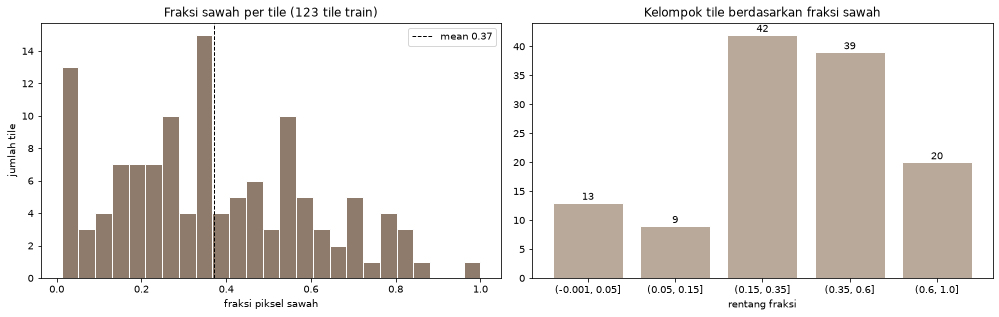

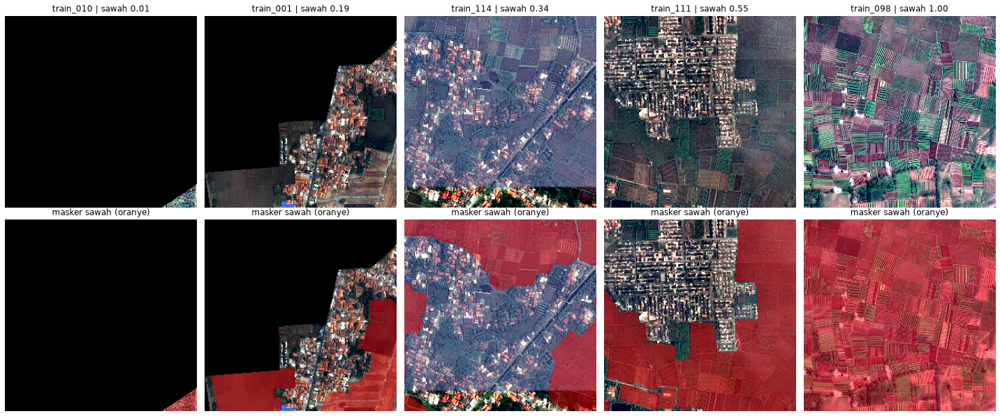

In [ ]:
tile_frac = Y_train.reshape(len(Y_train), -1).mean(1)
tile_valid = np.array([(x.max(-1) > 0).mean() for x in X_train])
tile_frac_valid = np.array([y[x.max(-1) > 0].mean() for x, y in zip(X_train, Y_train)])
print(f'fraksi sawah per tile : mean {tile_frac.mean():.3f} | median {np.median(tile_frac):.3f} | min {tile_frac.min():.4f} | max {tile_frac.max():.4f}')
print(f'fraksi sawah area valid: mean {tile_frac_valid.mean():.3f} | median {np.median(tile_frac_valid):.3f}')
print(f'piksel sawah total     : {Y_train.mean():.3f} dari seluruh piksel train')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(tile_frac, bins=25, color='#8E7B6B', edgecolor='white')
ax[0].axvline(tile_frac.mean(), color='k', ls='--', lw=1, label=f'mean {tile_frac.mean():.2f}')
ax[0].set_title('Fraksi sawah per tile (123 tile train)')
ax[0].set_xlabel('fraksi piksel sawah')
ax[0].set_ylabel('jumlah tile')
ax[0].legend()
bins = [0, 0.05, 0.15, 0.35, 0.6, 1.0]
counts = pd.cut(tile_frac, bins, include_lowest=True).value_counts().sort_index()
ax[1].bar([str(b) for b in counts.index], counts.values, color='#B8A99A', edgecolor='white')
for k, v in enumerate(counts.values):
    ax[1].text(k, v + 0.5, str(v), ha='center')
ax[1].set_title('Kelompok tile berdasarkan fraksi sawah')
ax[1].set_xlabel('rentang fraksi')
plt.tight_layout()
plt.show()

order = np.argsort(tile_frac)
pick = [order[int(q * (len(order) - 1))] for q in (0.0, 0.25, 0.5, 0.75, 1.0)]
fig, ax = plt.subplots(2, 5, figsize=(20, 8.4))
for c, i in enumerate(pick):
    ax[0, c].imshow(X_train[i][::4, ::4])
    ax[0, c].set_title(f'{train_files[i].stem} | sawah {tile_frac[i]:.2f}')
    ax[1, c].imshow(X_train[i][::4, ::4])
    ax[1, c].imshow(np.ma.masked_where(Y_train[i][::4, ::4] == 0, Y_train[i][::4, ::4]), cmap='autumn', alpha=0.45)
    ax[1, c].set_title('masker sawah (oranye)')
    ax[0, c].axis('off')
    ax[1, c].axis('off')
plt.tight_layout()
plt.show()

> ### Insights
> Tidak ada tile train tanpa sawah (minimum 1.1%), dan sebagian besar tile memiliki 15 sampai 60% sawah. Fraksi pada area valid lebih tinggi daripada fraksi per tile karena sebagian tile tertutup NoData.
>
> Tile dengan sawah di bawah 15% adalah kelompok tersulit karena sedikit piksel *false positive* sudah menurunkan IoU tile tersebut secara drastis.

---

## Sampel Tile Test

Tile test dilihat secara visual (tanpa label) untuk mengenali kondisi akuisisi yang mungkin tidak terwakili di train.

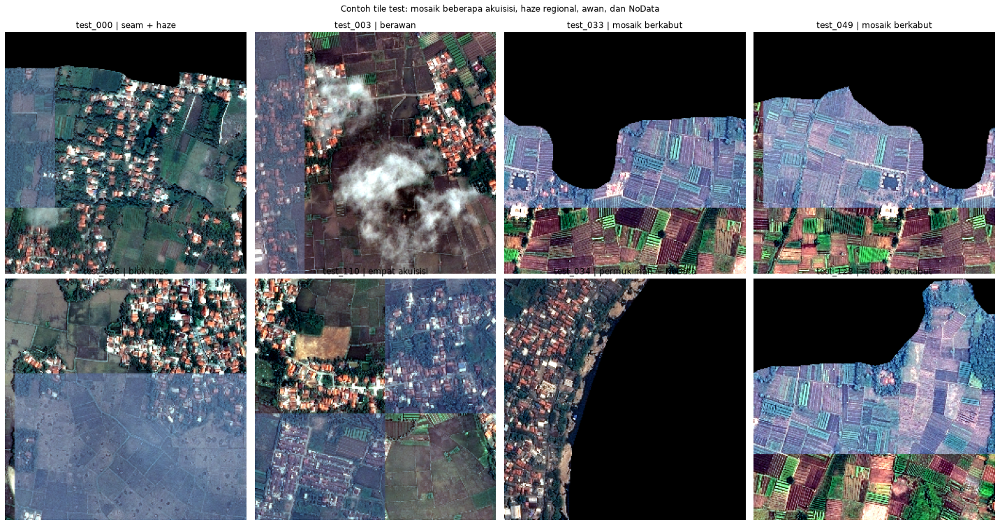

In [ ]:
show_test = {'test_000': 'seam + haze', 'test_003': 'berawan', 'test_033': 'mosaik berkabut', 'test_049': 'mosaik berkabut',
             'test_096': 'blok haze', 'test_110': 'empat akuisisi', 'test_034': 'permukiman + NoData', 'test_128': 'mosaik berkabut'}
fig, ax = plt.subplots(2, 4, figsize=(20, 10.4))
for a, (tid, note) in zip(ax.flat, show_test.items()):
    a.imshow(X_test[test_index[tid]][::4, ::4])
    a.set_title(f'{tid} | {note}')
    a.axis('off')
plt.suptitle('Contoh tile test: mosaik beberapa akuisisi, haze regional, awan, dan NoData', y=1.0)
plt.tight_layout()
plt.show()

> ### Insights
> Banyak tile test adalah mosaik beberapa akuisisi: satu blok tampak berkabut keunguan dengan kontras rendah, blok lain sangat jenuh. Kondisi ini menjadi dasar augmentasi haze regional pada bagian Prapemrosesan.

---

## Stretch per Tile dan NoData

Dua hipotesis diuji pada data yang dimuat: setiap tile di-*stretch* persentil per channel secara mandiri (temuan 4), dan NoData adalah komponen hitam besar hasil *clipping* AOI, bukan sembarang piksel bernilai 0 (temuan 6 dan 7).

In [7]:
def nodata_mask(img, min_area=CFG.NODATA_AREA):
    black = (img.max(-1) == 0).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(black, connectivity=8)
    keep = st[:, cv2.CC_STAT_AREA] >= min_area
    keep[0] = False
    return keep[lab]

sat255, nod_px, nod_pos = [], 0, 0
for x, y in zip(X_train, Y_train):
    v = x.max(-1) > 0
    sat255.append((x[v] == 255).mean(0))
    nd = nodata_mask(x)
    nod_px += nd.sum()
    nod_pos += y[nd].sum()
sat255 = np.array(sat255)
NOD_TR = np.stack([nodata_mask(x) for x in X_train])
NOD_TE = np.stack([nodata_mask(x) for x in X_test])
print('saturated-255 fraction per channel, median over tiles:', np.median(sat255, 0).round(4))
print(f'NoData px: {nod_px:,}  sawah inside NoData: {nod_pos:,} ({nod_pos / nod_px:.5%})')

saturated-255 fraction per channel, median over tiles: [0.0203 0.0203 0.0203]
NoData px: 23,260,927  sawah inside NoData: 3,170 (0.01363%)


saturasi 255 per tile (rata-rata channel): train median 0.0203 | test median 0.0203
fraksi NoData per tile: train mean 0.180 | test mean 0.131 | tile >50% NoData: train 21, test 12


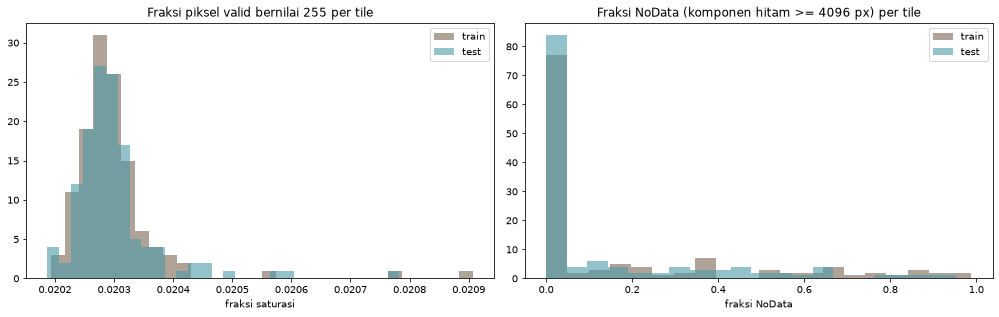

In [ ]:
sat255_te = np.array([(x[x.max(-1) > 0] == 255).mean(0) for x in X_test])
nod_frac_tr, nod_frac_te = NOD_TR.reshape(len(NOD_TR), -1).mean(1), NOD_TE.reshape(len(NOD_TE), -1).mean(1)
print(f'saturasi 255 per tile (rata-rata channel): train median {np.median(sat255.mean(1)):.4f} | test median {np.median(sat255_te.mean(1)):.4f}')
print(f'fraksi NoData per tile: train mean {nod_frac_tr.mean():.3f} | test mean {nod_frac_te.mean():.3f} | tile >50% NoData: train {(nod_frac_tr > .5).sum()}, test {(nod_frac_te > .5).sum()}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(sat255.mean(1), bins=30, alpha=0.7, label='train', color='#8E7B6B')
ax[0].hist(sat255_te.mean(1), bins=30, alpha=0.6, label='test', color='#4C9AA8')
ax[0].set_title('Fraksi piksel valid bernilai 255 per tile')
ax[0].set_xlabel('fraksi saturasi')
ax[0].legend()
ax[1].hist(nod_frac_tr, bins=20, alpha=0.7, label='train', color='#8E7B6B')
ax[1].hist(nod_frac_te, bins=20, alpha=0.6, label='test', color='#4C9AA8')
ax[1].set_title('Fraksi NoData (komponen hitam >= 4096 px) per tile')
ax[1].set_xlabel('fraksi NoData')
ax[1].legend()
plt.tight_layout()
plt.show()

> ### Insights
> Fraksi saturasi 255 sekitar 2% pada hampir semua tile train dan test membuktikan *stretch* per tile. Konsekuensinya, augmentasi fotometrik harus diakhiri *re-stretch*, sebab tanpa itu model melihat tile yang tidak pernah ada di data.
>
> Hanya 0.014% piksel NoData berisi sawah, sehingga memaksa prediksi 0 pada komponen hitam berukuran minimal 4096 piksel aman dan menghapus *false positive* di tepi AOI.

---

## Duplikasi: Tile Overlap Stride 512

Deteksi overlap seluruh pasangan (`eda/03b`, *phase correlation* pada gradien + verifikasi NCC + 8 transformasi D4) menemukan 104 pasangan: 93 train-train, 11 test-test, dan 0 train-test, semuanya bergeser kelipatan 512 piksel. Satu pasangan diperlihatkan di bawah untuk melihat apa yang sebenarnya diduplikasi.

label IoU di area overlap: 1.0000
MAE piksel mentah: 43.85 | setelah affine per channel: 0.51
gain per channel (R, G, B): [1.55, 1.698, 1.503] | offset: [-16.5, -14.4, 19.8]


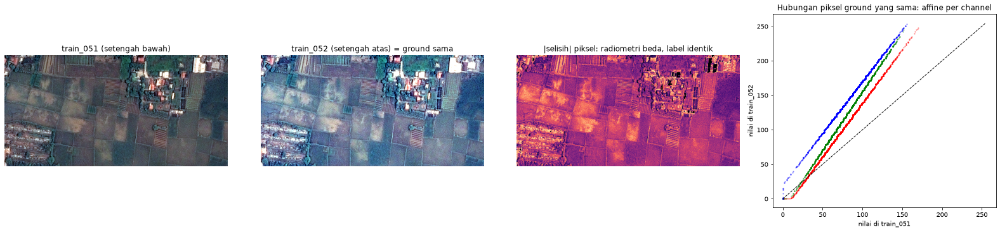

In [ ]:
ia, ib = [i for i, f in enumerate(train_files) if f.stem in ('train_051', 'train_052')]
# eda/03b: content of train_052 at (y, x) equals content of train_051 at (y + 512, x)
ov_a, ov_b = X_train[ia][512:].astype(np.float32), X_train[ib][:512].astype(np.float32)
ov_ma, ov_mb = Y_train[ia][512:], Y_train[ib][:512]
ov_v = (ov_a.max(-1) > 0) & (ov_b.max(-1) > 0) & (ov_a.max(-1) < 255) & (ov_b.max(-1) < 255)
fit = [np.polyfit(ov_a[..., c][ov_v], ov_b[..., c][ov_v], 1) for c in range(3)]
ov_pred = np.stack([fit[c][0] * ov_a[..., c] + fit[c][1] for c in range(3)], -1)
lab_iou = (ov_ma & ov_mb).sum() / max((ov_ma | ov_mb).sum(), 1)
print(f'label IoU di area overlap: {lab_iou:.4f}')
print(f'MAE piksel mentah: {np.abs(ov_a - ov_b)[ov_v].mean():.2f} | setelah affine per channel: {np.abs(ov_pred - ov_b)[ov_v].mean():.2f}')
print('gain per channel (R, G, B):', [round(float(f[0]), 3) for f in fit], '| offset:', [round(float(f[1]), 1) for f in fit])

fig, ax = plt.subplots(1, 4, figsize=(22, 5.2))
ax[0].imshow(ov_a.astype(np.uint8)[::2, ::2])
ax[0].set_title('train_051 (setengah bawah)')
ax[1].imshow(ov_b.astype(np.uint8)[::2, ::2])
ax[1].set_title('train_052 (setengah atas) = ground sama')
ax[2].imshow(np.abs(ov_a - ov_b).mean(-1)[::2, ::2], cmap='magma')
ax[2].set_title('|selisih| piksel: radiometri beda, label identik')
for a in ax[:3]:
    a.axis('off')
sel = np.random.default_rng(0).choice(np.flatnonzero(ov_v), 4000, replace=False)
for c, col in enumerate(('r', 'g', 'b')):
    ax[3].scatter(ov_a[..., c].ravel()[sel], ov_b[..., c].ravel()[sel], s=2, alpha=0.3, c=col)
ax[3].plot([0, 255], [0, 255], 'k--', lw=1)
ax[3].set_xlabel('nilai di train_051')
ax[3].set_ylabel('nilai di train_052')
ax[3].set_title('Hubungan piksel ground yang sama: affine per channel')
plt.tight_layout()
plt.show()

> ### Insights
> Label pada area overlap identik, tetapi pikselnya berbeda karena *stretch* per tile. Hubungan piksel antar salinan hampir sempurna affine per channel (R2 0.999 pada seluruh 93 pasangan, `eda/04`), dengan gain yang hampir sama antar channel. Variasi antar tile adalah kontras dan kecerahan, bukan pergeseran hue.
>
> Dua implikasi: *split* acak akan membocorkan ground yang sama ke validasi, dan pasangan overlap memberi bank gain/offset nyata (log-gain std 0.28, korelasi gain-offset -0.83) untuk augmentasi kontras yang realistis.

---

## Pergeseran Domain Train ke Test

Threshold optimal di *leaderboard* jauh lebih rendah daripada di validasi, sehingga sumber pergeseran domain perlu diidentifikasi. Spektrum radial ternormalisasi menguji apakah test lebih buram atau memiliki resolusi berbeda; statistik warna per tile menguji pergeseran radiometrik global.

train asli         jarak L1 ke spektrum test: 0.046
train + blur s0.3  jarak L1 ke spektrum test: 0.030
train + blur s0.5  jarak L1 ke spektrum test: 0.263
train + blur s1.0  jarak L1 ke spektrum test: 1.416


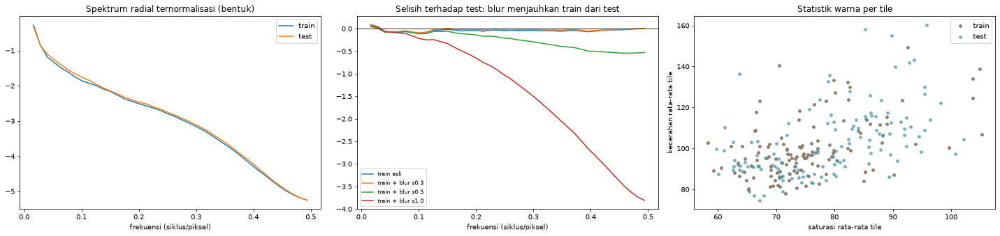

In [ ]:
PSD_W = 256
_fy, _fx = np.meshgrid(np.fft.fftfreq(PSD_W), np.fft.fftfreq(PSD_W), indexing='ij')
PSD_BINS = np.linspace(0.01, 0.5, 41)
PSD_IDX = np.digitize(np.sqrt(_fx ** 2 + _fy ** 2), PSD_BINS) - 1
PSD_OK = (PSD_IDX >= 0) & (PSD_IDX < 40)
PSD_HANN = np.outer(np.hanning(PSD_W), np.hanning(PSD_W)).astype(np.float32)
PSD_F = (PSD_BINS[1:] + PSD_BINS[:-1]) / 2

def radial_psd(img, sigma=0.0):
    g = cv2.cvtColor(np.ascontiguousarray(img), cv2.COLOR_RGB2GRAY).astype(np.float32)
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    v = img.max(-1) > 0
    acc, n = np.zeros(40), 0
    for y in range(0, 1024, PSD_W):
        for x in range(0, 1024, PSD_W):
            if v[y:y + PSD_W, x:x + PSD_W].mean() < 0.999:
                continue
            w = g[y:y + PSD_W, x:x + PSD_W]
            P = np.abs(np.fft.fft2((w - w.mean()) * PSD_HANN)) ** 2
            acc += np.bincount(PSD_IDX[PSD_OK], P[PSD_OK], 40) / np.bincount(PSD_IDX[PSD_OK], minlength=40)
            n += 1
    return np.log10(acc / acc.sum()) if n else None

def mean_psd(imgs, sigma=0.0):
    curves = [c for c in (radial_psd(x, sigma) for x in imgs) if c is not None]
    return np.mean(curves, 0)

psd_tr, psd_te = mean_psd(X_train), mean_psd(X_test)
psd_var = {'train asli': psd_tr, **{f'train + blur s{s}': mean_psd(X_train[::2], s) for s in (0.3, 0.5, 1.0)}}
for k, v in psd_var.items():
    print(f'{k:18s} jarak L1 ke spektrum test: {np.abs(v - psd_te).mean():.3f}')

hsv_stats = lambda arr: np.array([cv2.cvtColor(np.ascontiguousarray(x), cv2.COLOR_RGB2HSV)[x.max(-1) > 0].mean(0) for x in arr])
hsv_tr, hsv_te = hsv_stats(X_train), hsv_stats(X_test)

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
ax[0].plot(PSD_F, psd_tr, label='train')
ax[0].plot(PSD_F, psd_te, label='test')
ax[0].set_title('Spektrum radial ternormalisasi (bentuk)')
ax[0].set_xlabel('frekuensi (siklus/piksel)')
ax[0].legend()
for k, v in psd_var.items():
    ax[1].plot(PSD_F, v - psd_te, label=k)
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_title('Selisih terhadap test: blur menjauhkan train dari test')
ax[1].set_xlabel('frekuensi (siklus/piksel)')
ax[1].legend(fontsize=8)
ax[2].scatter(hsv_tr[:, 1], hsv_tr[:, 2], s=14, label='train', color='#8E7B6B')
ax[2].scatter(hsv_te[:, 1], hsv_te[:, 2], s=14, label='test', color='#4C9AA8', alpha=0.7)
ax[2].set_xlabel('saturasi rata-rata tile')
ax[2].set_ylabel('kecerahan rata-rata tile')
ax[2].set_title('Statistik warna per tile')
ax[2].legend()
plt.tight_layout()
plt.show()

> ### Insights
> Bentuk spektrum train dan test hampir identik. *Blur* sangat ringan (sigma 0.3) netral, sedangkan sigma 0.5 sudah menjauhkan train dari test sekitar 6 kali lipat dan sigma 1.0 sekitar 30 kali. Test tidak lebih buram dan resolusinya sama, sehingga augmentasi *blur* dibuang. Temuan lama bahwa test lebih buram berasal dari Laplacian yang bergantung pada kontras *stretch*, bukan pada ketajaman.
>
> *Adversarial validation* pada patch 128 piksel (`eda/11`, LightGBM, GroupKFold per tile) memberi AUC 0.745 untuk train vs test, setara AUC antar *fold* train (0.64 sampai 0.79). Pergeseran citra ke test tidak lebih besar daripada pergeseran antar *fold*.

---

## Mosaik Akuisisi dan Haze Regional

Tile paling mirip test menurut *adversarial validation* adalah mosaik dua akuisisi. Profil saturasi per baris dan kolom memperlihatkan batas akuisisi sebagai lompatan tajam.

test_033: lompatan saturasi maksimum antar baris 43.9, antar kolom 12.6
test_049: lompatan saturasi maksimum antar baris 38.4, antar kolom 30.4
test_096: lompatan saturasi maksimum antar baris 11.3, antar kolom 12.4
test_000: lompatan saturasi maksimum antar baris 15.5, antar kolom 8.8


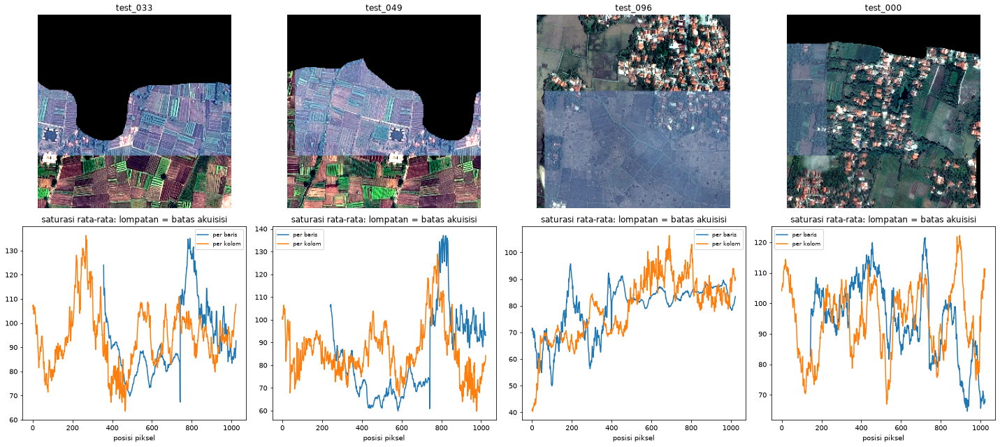

In [ ]:
def seam_profile(img):
    hsv = cv2.cvtColor(np.ascontiguousarray(img), cv2.COLOR_RGB2HSV).astype(np.float32)
    v = img.max(-1) > 0
    rows = np.array([hsv[r, v[r], 1].mean() if v[r].sum() > 50 else np.nan for r in range(1024)])
    cols = np.array([hsv[v[:, c], c, 1].mean() if v[:, c].sum() > 50 else np.nan for c in range(1024)])
    return rows, cols

seam_ids = ['test_033', 'test_049', 'test_096', 'test_000']
fig, ax = plt.subplots(2, 4, figsize=(20, 9))
for c, tid in enumerate(seam_ids):
    img = X_test[test_index[tid]]
    rows, cols = seam_profile(img)
    ax[0, c].imshow(img[::4, ::4])
    ax[0, c].set_title(tid)
    ax[0, c].axis('off')
    ax[1, c].plot(rows, label='per baris')
    ax[1, c].plot(cols, label='per kolom')
    ax[1, c].set_title('saturasi rata-rata: lompatan = batas akuisisi')
    ax[1, c].set_xlabel('posisi piksel')
    ax[1, c].legend(fontsize=8)
    jump_r, jump_c = np.nanmax(np.abs(np.diff(rows))), np.nanmax(np.abs(np.diff(cols)))
    print(f'{tid}: lompatan saturasi maksimum antar baris {jump_r:.1f}, antar kolom {jump_c:.1f}')
plt.tight_layout()
plt.show()

> ### Insights
> Haze di test bersifat regional: satu blok akuisisi berkabut, sementara *stretch* dihitung atas seluruh tile. Klaster tampilan berkabut 1.9 sampai 2.2 kali lebih sering di test, dan ketidakpastian model di klaster tersebut 4 kali lebih tinggi daripada di OOF (`eda/12`). Augmentasi haze harus meniru struktur blok ini, bukan kabut merata.

---

## Ringkasan Temuan EDA

Tabel berikut merangkum seluruh temuan EDA yang mengubah desain *pipeline*, termasuk yang dijalankan di luar notebook.

| # | Temuan EDA | Bukti | Konsekuensi di pipeline |
|---|---|---|---|
| 1 | Tile dipotong dengan stride 512 (overlap 50%) | 93 pasangan train overlap, NCC>0.97, label di overlap identik (IoU 1.0) | Random K-fold bocor; dipakai 5 fold spasial + purge tile yang berbagi piksel |
| 2 | Train hanya setara 57.5 tile unik | redundansi x2.14 | Augmentasi geometri dan fotometrik wajib, epoch dihitung per step bukan per tile |
| 3 | Tidak ada overlap train-test | 0 pasangan, 0 adjacency | Tidak ada leakage lintas split, CV spasial merepresentasikan test |
| 4 | Setiap tile di-stretch per channel sendiri | ~1% piksel valid clip ke 0, tepat ~2.03% saturasi 255 di semua tile | Augmentasi fotometrik harus diakhiri re-stretch, kalau tidak menghasilkan tile yang tidak pernah ada |
| 5 | Ground yang sama tampil beda antar tile | affine per channel R2=0.999, log-gain std 0.28, corr(gain, offset)=-0.83 | Augmentasi kontras di sekitar mean tile, deviasi per channel kecil (0.04), hue jitter tidak dipakai |
| 6 | NoData = region hitam besar dari clipping AOI | 18% piksel train, 13% test; sawah di dalamnya 0.013% | Post-processing: region hitam >=4096 px dipaksa 0 |
| 7 | Piksel hitam kecil di area valid bukan NoData | 1.18 juta px, 17% di antaranya sawah | NoData dideteksi dengan connected component, bukan `pixel==0` |
| 8 | Label = poligon digitasi kasar | 26 vertex per kontur, segmen 57 px; IoU ceiling stride 4 = 0.9985, stride 32 = 0.976 | Decoder stride 4 cukup; ViT/16 tanpa decoder kehilangan ~2% IoU |
| 9 | Test lebih berawan dan lebih banyak seam | seam 25.6% test vs 14.6% train; awan >1% di 3.9% tile test vs 0% train | Augmentasi awan dan seam (+ re-stretch), label tetap karena poligon ditarik menembus awan |
| 10 | Test TIDAK lebih blur (koreksi temuan lama) | spektrum radial ternormalisasi train vs test hampir identik, HF KS p=0.12; blur sigma 0.5 menjauhkan train dari test (L1 0.075 -> 0.317) | Blur tidak dipakai; selisih Laplacian lama berasal dari kontras stretch, bukan resolusi |
| 11 | Error OOF berupa blok sepetak, bukan batas | 82% FP dan 89% FN di blob >=4096 px, hanya 22% error di pita batas | Kapasitas semantik (backbone besar, konteks 1024 penuh) lebih penting dari resolusi |
| 12 | Model under-confident di blok test | pita 0.1<p<0.5 = 5.2% piksel test vs 3.4% OOF; tile dengan pita >5%: 56/129 test vs 24/123 train | Threshold submission rendah (0.10 sampai 0.15) dari kurva LB; OOF dicek agar biayanya kecil |
| 13 | Pergeseran citra train-test setara pergeseran antar fold | adversarial AUC patch train vs test 0.745, val fold vs train 0.64 sampai 0.79 | Shift bukan radiometrik global; augmentasi diarahkan ke blok mosaik (seam, haze regional) |
| 14 | Haze nyata bersifat regional (satu blok akuisisi) | cluster tampilan haze 1.9 sampai 2.2x lebih sering di test dan ketidakpastian 4x lebih tinggi dari OOF | Haze diterapkan pada blok lalu tile di-stretch ulang; haze global + re-stretch terbukti no-op (selisih 0.36 per piksel) |
| 15 | Piksel gelap kecil (bukan NoData) bolong di bawah awan sintetis | 1.17% piksel hitam di bawah awan versi lama, 0% setelah fix | Awan dan haze memakai NoData berbasis komponen besar |
| 16 | Sampling tile seragam mengulang ground yang sama | ground 512 px dicakup 1 sampai 4 tile; densitas max/min 4.0, efektif 189/230 sel | Bobot sampling per tile 1/coverage (efektif 219/230 sel) |

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Prapemrosesan dan Augmentasi <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Setiap augmentasi diturunkan dari temuan EDA, diterapkan pada sampel tile per tipe, diperiksa secara visual, lalu diukur secara kuantitatif. Dua augmentasi yang benar secara teori ternyata rusak saat dicoba dan sudah diperbaiki.

---

## Justifikasi Augmentasi

| Augmentasi | Dasar EDA | p (v3) | Status |
|---|---|---|---|
| D4 (rot90 + flip) | tidak ada orientasi kanonik pada citra nadir | 1.0 | dipakai |
| Rotasi bebas + skala 0.85 sampai 1.2 | petak test sedikit lebih besar (komponen median 17k vs 11k px) | 0.3 | dipakai, sudut diisi 0 = NoData |
| Kontras di sekitar mean tile | gain/offset nyata dari 93 pasangan overlap | 0.5 | dipakai |
| Seam (kontras pada satu blok) + *re-stretch* | seam di 26% tile test vs 15% train | 0.2 | dipakai |
| Haze per blok + *re-stretch* | haze regional, 2x lebih sering di test | 0.25 | diperbaiki (versi global = no-op) |
| Awan + *re-stretch* | awan di 3.9% tile test, 0% train | 0.15 | diperbaiki (bintik hitam) |
| *Blur* | spektrum test tidak lebih buram | 0 | dibuang |
| ColorJitter hue/saturasi | gain antar channel hampir sama; tidak menambah ketahanan awan di *ablation* | 0 | dibuang |
| *Random crop* 768 dari tile 1024 | variasi translasi; crop 1024 (v2) overfit ke domain train | 1.0 | dipakai |

---

## Fungsi Augmentasi

Augmentasi radiometrik bekerja pada piksel valid dan diakhiri *re-stretch* persentil 1/98 per channel. Haze diterapkan pada satu blok (*half-plane* atau sudut) agar *re-stretch* seluruh tile tidak membatalkannya. Awan dan haze memakai NoData berbasis komponen besar.

In [9]:
def valid_of(img):
    return img.max(-1) > 0

def restretch(img, lo=1.0, hi=98.0):
    v = valid_of(img)
    if v.sum() < 1000:
        return img
    out = img.astype(np.float32)
    for c in range(3):
        a, b = np.percentile(out[..., c][v], [lo, hi])
        out[..., c][v] = np.clip((out[..., c][v] - a) / max(b - a, 1.0) * 255, 0, 255)
    return out.round().astype(np.uint8)

def contrast_aug(img, rng, region=None):
    v = valid_of(img) if region is None else valid_of(img) & region
    if v.sum() < 100:
        return img
    out = img.astype(np.float32)
    mu = out[v].mean(0)
    # log-gain std 0.28 shared + 0.04 per channel, offset std 5 (fitted on train-train overlaps)
    g = np.exp(np.clip(rng.normal(0, 0.28), -0.5, 0.5) + rng.normal(0, 0.04, 3))
    b = rng.normal(0, 5, 3)
    out[v] = np.clip((out[v] - mu) * g + mu + b, 0, 255)
    return out.round().astype(np.uint8)

def block_region(h, w, rng):
    region = np.zeros((h, w), bool)
    k1, k2 = rng.integers(h // 5, 4 * h // 5, 2)
    mode = rng.integers(3)
    if mode == 0:
        region[:k1] = True
    elif mode == 1:
        region[:, :k1] = True
    else:
        region[:k1, :k2] = True
    return ~region if rng.random() < 0.5 else region

def seam_aug(img, rng):
    return restretch(contrast_aug(img, rng, block_region(*img.shape[:2], rng)))

def fractal_noise(h, w, rng, octaves=5):
    n = np.zeros((h, w), np.float32)
    for k in range(octaves):
        s = 2 ** (k + 2)
        n += cv2.resize(rng.random((s, s)).astype(np.float32), (w, h), interpolation=cv2.INTER_CUBIC) / (1.6 ** k)
    n -= n.min()
    return n / (n.max() + 1e-6)

def cloud_aug(img, rng):
    h, w = img.shape[:2]
    n = fractal_noise(h, w, rng)
    t = np.quantile(n, 1 - rng.uniform(0.05, 0.3))
    alpha = np.clip((n - t) / (1 - t + 1e-6) * 2.5, 0, 1) * rng.uniform(0.3, 0.8)
    alpha = cv2.GaussianBlur(alpha, (0, 0), 6)[..., None]
    out = img.astype(np.float32) * (1 - alpha) + rng.uniform(215, 250, 3).astype(np.float32) * alpha
    out[nodata_mask(img)] = 0
    return restretch(out.round().astype(np.uint8))

def haze_aug(img, rng):
    region = block_region(*img.shape[:2], rng) & ~nodata_mask(img)
    s = rng.uniform(0.05, 0.4)
    tint = np.array([rng.uniform(140, 180), rng.uniform(160, 195), rng.uniform(205, 245)], np.float32)
    out = img.astype(np.float32)
    out[region] = out[region] * (1 - s) + tint * s
    return restretch(out.round().astype(np.uint8))

def blur_aug(img, rng):
    out = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.3, 0.8))
    out[~valid_of(img)] = 0
    return restretch(out)

def d4(img, msk, rng):
    k = int(rng.integers(4))
    img, msk = np.rot90(img, k), np.rot90(msk, k)
    if rng.random() < 0.5:
        img, msk = img[:, ::-1], msk[:, ::-1]
    return np.ascontiguousarray(img), np.ascontiguousarray(msk)

def rotate_scale(img, msk, rng):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-180, 180), rng.uniform(0.85, 1.2))
    img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
    msk = cv2.warpAffine(msk, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
    return img, msk

def augment(img, msk, rng):
    img, msk = d4(img, msk, rng)
    if rng.random() < CFG.P_ROTATE:
        img, msk = rotate_scale(img, msk, rng)
    if rng.random() < CFG.P_CONTRAST:
        img = contrast_aug(img, rng)
    if rng.random() < CFG.P_SEAM:
        img = seam_aug(img, rng)
    if rng.random() < CFG.P_HAZE:
        img = haze_aug(img, rng)
    if rng.random() < CFG.P_CLOUD:
        img = cloud_aug(img, rng)
    if rng.random() < CFG.P_BLUR:
        img = blur_aug(img, rng)
    return img, msk

---

## Visualisasi Augmentasi per Tipe Tile

Augmentasi diterapkan pada satu tile per tipe (sawah dominan, permukiman, NoData besar, seam). Kontur masker hijau harus tetap menempel pada petak yang sama setelah transformasi geometri.

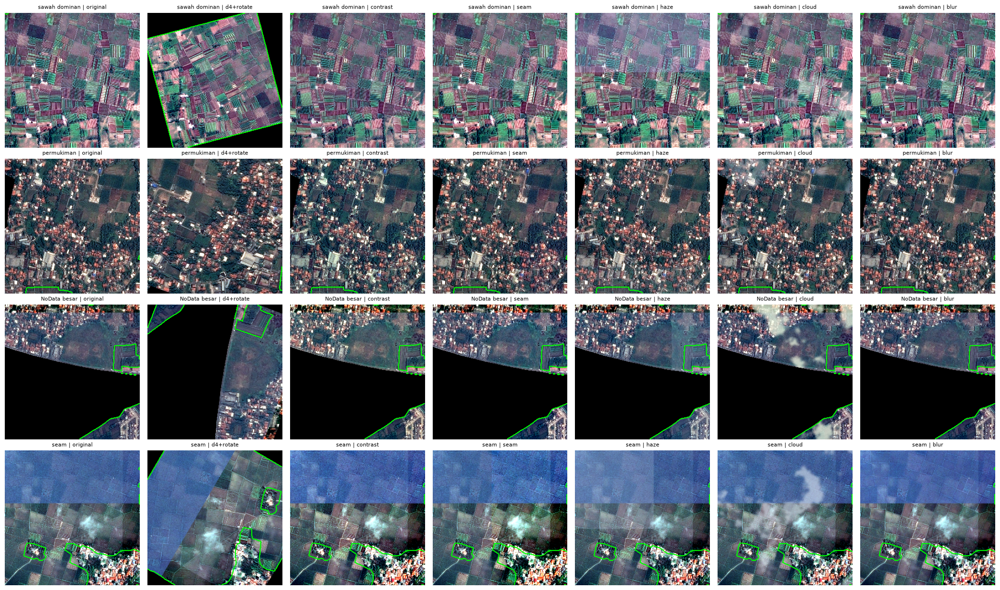

In [10]:
frac = Y_train.reshape(len(Y_train), -1).mean(1)
valid = np.array([valid_of(x).mean() for x in X_train])
reps = {'sawah dominan': int(np.argmax(frac * (valid > .95))), 'permukiman': int(np.argmin(frac + (valid < .95))),
        'NoData besar': int(np.argmin(abs(valid - .5))), 'seam': 73}
ops = {'original': None, 'd4+rotate': 'geo', 'contrast': contrast_aug, 'seam': seam_aug,
       'haze': haze_aug, 'cloud': cloud_aug, 'blur': blur_aug}
rng = np.random.default_rng(0)
fig, ax = plt.subplots(len(reps), len(ops), figsize=(3 * len(ops), 3.1 * len(reps)))
for r, (name, i) in enumerate(reps.items()):
    for c, (op, f) in enumerate(ops.items()):
        im, mk = X_train[i], Y_train[i]
        if f == 'geo':
            im, mk = rotate_scale(*d4(im, mk, rng), rng)
        elif f is not None:
            im = f(im.copy(), rng)
        ax[r, c].imshow(im[::4, ::4])
        ax[r, c].contour(mk[::4, ::4], colors='lime', linewidths=.6)
        ax[r, c].set_title(f'{name} | {op}', fontsize=8)
        ax[r, c].axis('off')
plt.tight_layout()
plt.show()

> ### Insights
> Kontras dan seam meniru variasi radiometrik nyata antar tile tanpa mengubah hue, karena sawah berbagai fase (hijau, tergenang, bera) dibedakan dari latar lewat tekstur petak, bukan warna absolut.
>
> Masker tidak diubah oleh augmentasi fotometrik karena label poligon memang ditarik menembus awan (rate sawah di bawah awan 0.74, setara area sekitarnya 0.77).

---

## Verifikasi Kuantitatif Augmentasi

Pemeriksaan visual saja tidak cukup. Setiap operasi diukur pada sampel tile: besar perubahan citra, fraksi saturasi 255 (harus tetap sekitar 2% seperti tile asli), dan piksel hitam murni di luar NoData.

In [11]:
def global_haze_old(img, rng):
    s = rng.uniform(0.1, 0.35)
    out = img.astype(np.float32) * (1 - s) + np.array([180, 190, 225], np.float32) * s
    out[~valid_of(img)] = 0
    return restretch(out.round().astype(np.uint8))

check_ops = {'original': lambda x, r: x, 'contrast': contrast_aug, 'seam': seam_aug, 'haze global (lama)': global_haze_old,
             'haze blok (v3)': haze_aug, 'cloud': cloud_aug, 'blur': blur_aug}
rows = []
for name, f in check_ops.items():
    rng = np.random.default_rng(3)
    diff, sat, holes = [], [], []
    for i in range(0, len(X_train), 6):
        x = X_train[i]
        nd = nodata_mask(x)
        a = f(x.copy(), rng)
        diff.append(np.abs(a.astype(int) - restretch(x.copy()).astype(int))[~nd].mean())
        sat.append((a[~nd] == 255).any(-1).mean())
        holes.append((a.max(-1)[~nd] == 0).mean())
    rows.append(dict(op=name, mean_abs_change=np.mean(diff), sat255_frac=np.mean(sat), black_px_outside_nodata=np.mean(holes)))
print(pd.DataFrame(rows).round(4).to_string(index=False))

                op  mean_abs_change  sat255_frac  black_px_outside_nodata
          original           0.5210       0.0253                   0.0107
          contrast           8.5617       0.0239                   0.0217
              seam           4.7308       0.0309                   0.0153
haze global (lama)           0.3482       0.0253                   0.0113
    haze blok (v3)          12.9384       0.0274                   0.0087
             cloud          13.1185       0.0262                   0.0089
              blur           2.7114       0.0257                   0.0120


> ### Insights
> Haze global versi lama hanya mengubah 0.35 nilai per piksel setelah *re-stretch*. Haze adalah affine per channel dan *re-stretch* persentil per channel membatalkannya, sehingga pada run sebelumnya model tidak pernah melihat haze. Haze per blok mengubah citra 12.9 nilai per piksel, sebanding dengan awan.
>
> Semua operasi mempertahankan fraksi saturasi di kisaran tile asli (0.024 sampai 0.031), sehingga tile augmentasi tetap berada di distribusi yang sama dengan data asli.

---

## Perbaikan Bintik Hitam di Bawah Awan

Piksel gelap kecil yang ter-*clip* ke 0 oleh *stretch* bukan NoData, tetapi versi awal awan memperlakukan semua piksel 0 sebagai NoData sehingga piksel tersebut tetap hitam di tengah awan putih. Versi perbaikan memakai `nodata_mask` berbasis komponen besar.

piksel hitam murni di bawah awan sintetis: versi lama 1.4081% | versi perbaikan 0.0000%


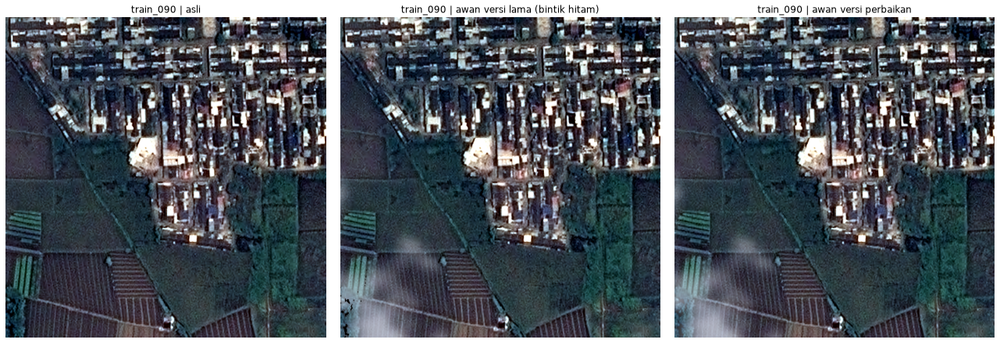

In [ ]:
def cloud_aug_old(img, rng):
    h, w = img.shape[:2]
    n = fractal_noise(h, w, rng)
    t = np.quantile(n, 1 - rng.uniform(0.05, 0.3))
    alpha = np.clip((n - t) / (1 - t + 1e-6) * 2.5, 0, 1) * rng.uniform(0.3, 0.8)
    alpha = cv2.GaussianBlur(alpha, (0, 0), 6)[..., None]
    out = img.astype(np.float32) * (1 - alpha) + rng.uniform(215, 250, 3).astype(np.float32) * alpha
    out[~valid_of(img)] = 0
    return restretch(out.round().astype(np.uint8))

def black_under_cloud(orig, aug):
    lifted = cv2.GaussianBlur(((aug.astype(np.float32).mean(-1) - orig.astype(np.float32).mean(-1)) > 40).astype(np.float32), (0, 0), 4) > 0.5
    region = lifted & ~nodata_mask(orig)
    return (aug.max(-1)[region] == 0).mean() if region.sum() > 1000 else np.nan

old_b, new_b = [], []
for i in range(0, len(X_train), 4):
    old_b.append(black_under_cloud(X_train[i], cloud_aug_old(X_train[i].copy(), np.random.default_rng(i))))
    new_b.append(black_under_cloud(X_train[i], cloud_aug(X_train[i].copy(), np.random.default_rng(i))))
print(f'piksel hitam murni di bawah awan sintetis: versi lama {np.nanmean(old_b):.4%} | versi perbaikan {np.nanmean(new_b):.4%}')

i = [k for k, f in enumerate(train_files) if f.stem == 'train_090'][0]
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, im, t in zip(ax, (X_train[i], cloud_aug_old(X_train[i].copy(), np.random.default_rng(5)), cloud_aug(X_train[i].copy(), np.random.default_rng(5))),
                    ('asli', 'awan versi lama (bintik hitam)', 'awan versi perbaikan')):
    a.imshow(im[300:812, 500:1012])
    a.set_title(f'train_090 | {t}')
    a.axis('off')
plt.tight_layout()
plt.show()

> ### Insights
> Bintik hitam di bawah awan sintetis hilang setelah perbaikan. Artefak seperti ini tidak pernah muncul pada citra nyata dan dapat dijadikan jalan pintas oleh model untuk mengenali citra augmentasi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Validasi Spasial dan DataLoader <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Tile train membentuk strip utara-selatan yang saling overlap, sedangkan test berada pada blok X yang berbeda. Validasi harus meniru kondisi tersebut: tidak ada piksel ground yang muncul di train dan validasi sekaligus.

---

## Fold Spasial dengan Purge

Layout tile direkonstruksi dari overlap dan kesinambungan tepi (`eda/03c`, 0 konflik). Setiap komponen dipotong menjadi pita kontigu, lalu untuk *fold* k, tile train yang berbagi piksel dengan tile validasi dibuang. Bobot `w` = rata-rata 1/coverage per tile disiapkan untuk *sampling* seimbang.

In [8]:
LAYOUT = '0,0,0,4 0,0,1,2 0,0,2,2 0,0,3,3 0,2,-1,4 0,2,0,2 0,2,1,2 0,2,2,3 0,2,3,3 0,2,4,3 1,0,0,0 0,2,11,4 0,2,12,2 0,2,13,2 2,0,0,1 2,0,1,1 2,0,2,3 2,0,3,3 2,0,4,3 2,0,5,3 0,3,10,1 0,3,11,4 0,3,12,2 0,3,13,2 2,1,-2,1 0,4,15,0 0,4,-2,4 0,4,-1,4 0,4,0,2 0,4,1,2 0,4,2,3 0,4,3,3 0,4,4,0 0,4,10,1 0,4,11,4 0,4,12,2 0,4,13,2 0,4,14,0 2,2,-2,1 3,0,0,2 2,2,-1,1 2,2,0,1 2,2,1,1 2,2,2,3 2,2,3,3 2,2,4,3 2,2,5,3 4,0,0,4 0,5,6,0 0,5,7,0 0,5,10,1 0,5,11,4 0,5,12,2 0,5,13,2 0,5,14,0 0,6,-3,4 0,6,15,0 0,6,-2,4 0,6,-1,4 0,6,0,2 0,6,1,2 0,6,2,3 0,6,3,3 0,6,4,0 0,6,-4,4 0,6,5,0 0,6,6,0 0,6,7,0 0,6,8,1 0,6,9,1 0,6,10,1 0,6,11,4 0,6,12,2 0,6,13,0 0,6,14,0 5,0,0,1 2,4,-2,1 0,7,15,0 2,4,-1,1 2,4,0,1 2,4,1,1 2,4,2,3 2,4,3,3 2,4,4,3 2,4,5,3 2,4,-3,1 0,7,5,0 0,7,6,0 0,7,7,1 0,7,8,1 0,7,9,1 0,7,10,4 0,7,11,4 0,7,12,2 0,7,13,0 0,7,14,0 6,0,0,1 0,8,-3,4 7,0,0,0 0,8,-2,4 0,8,-1,4 0,8,0,2 0,8,1,2 0,8,2,3 0,8,3,3 0,8,4,0 0,8,-4,4 0,8,5,0 0,8,6,0 0,8,7,1 0,8,8,1 0,8,9,1 0,8,10,4 0,8,11,4 0,8,12,2 0,8,13,0 0,8,14,0 0,1,0,2 0,1,1,2 0,1,2,3 0,1,3,3 0,1,11,4 0,1,12,4'
folds = pd.DataFrame([list(map(int, t.split(','))) for t in LAYOUT.split()], columns=['comp', 'hx', 'hy', 'fold'])
folds['id'] = [f.stem for f in train_files]

def train_ids_for(k):
    va = folds[folds.fold == k]
    keep = []
    for i, r in folds[folds.fold != k].iterrows():
        same = va[va.comp == r.comp]
        if not ((abs(same.hx - r.hx) < 2) & (abs(same.hy - r.hy) < 2)).any():
            keep.append(i)
    return np.array(keep)

for k in range(5):
    va = folds.index[folds.fold == k]
    print(f'fold {k}: val={len(va):3d} train={len(train_ids_for(k)):3d} val sawah frac={Y_train[va].mean():.3f}')

cells_cov = {}
for r in folds.itertuples():
    for dx in (0, 1):
        for dy in (0, 1):
            key = (r.comp, r.hx + dx, r.hy + dy)
            cells_cov[key] = cells_cov.get(key, 0) + 1
folds['w'] = [np.mean([1 / cells_cov[(r.comp, r.hx + dx, r.hy + dy)] for dx in (0, 1) for dy in (0, 1)]) for r in folds.itertuples()]
print(f'ground cells: {len(cells_cov)} | coverage counts: {pd.Series(cells_cov).value_counts().sort_index().to_dict()}')
print('balanced tile weight percentiles:', np.percentile(folds.w / folds.w.mean(), [0, 25, 50, 75, 100]).round(2))

fold 0: val= 25 train= 84 val sawah frac=0.362
fold 1: val= 26 train= 81 val sawah frac=0.333
fold 2: val= 24 train= 72 val sawah frac=0.393
fold 3: val= 24 train= 86 val sawah frac=0.384
fold 4: val= 24 train= 77 val sawah frac=0.386
ground cells: 230 | coverage counts: {1: 62, 2: 114, 3: 14, 4: 40}
balanced tile weight percentiles: [0.53 0.71 1.07 1.09 2.14]


sampling seragam  : densitas sel max/min 4.00 | sel efektif 189 dari 230
sampling seimbang : densitas sel max/min 3.36 | sel efektif 219 dari 230


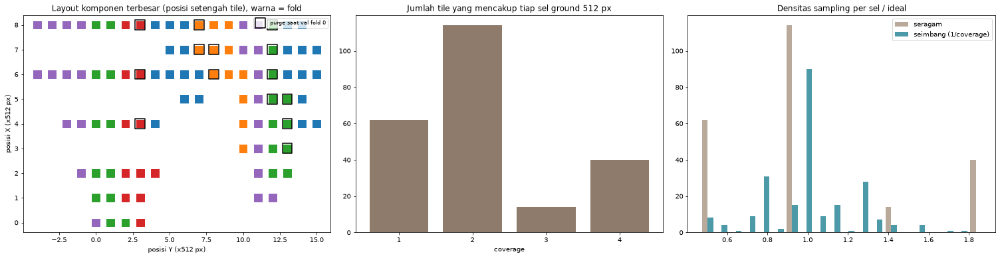

In [ ]:
cov = pd.Series(cells_cov)
dens_uni = {}
dens_bal = {}
for r in folds.itertuples():
    for dx in (0, 1):
        for dy in (0, 1):
            key = (r.comp, r.hx + dx, r.hy + dy)
            dens_uni[key] = dens_uni.get(key, 0) + 0.25
            dens_bal[key] = dens_bal.get(key, 0) + 0.25 * r.w
dens_uni, dens_bal = pd.Series(dens_uni), pd.Series(dens_bal)
dens_uni, dens_bal = dens_uni / dens_uni.sum(), dens_bal / dens_bal.sum()
for name, d in (('sampling seragam', dens_uni), ('sampling seimbang', dens_bal)):
    print(f'{name:18s}: densitas sel max/min {d.max() / d.min():.2f} | sel efektif {1 / (d ** 2).sum():.0f} dari {len(d)}')

fig, ax = plt.subplots(1, 3, figsize=(21, 5.5))
big = folds[folds.comp == 0]
sc = ax[0].scatter(big.hy, big.hx, c=big.fold, cmap='tab10', s=140, marker='s', vmin=0, vmax=9)
purged = folds.index[(folds.comp == 0) & (folds.fold != 0)].difference(train_ids_for(0))
ax[0].scatter(folds.hy[purged], folds.hx[purged], facecolors='none', edgecolors='k', s=220, marker='s', lw=1.5, label='purge saat val fold 0')
ax[0].set_title('Layout komponen terbesar (posisi setengah tile), warna = fold')
ax[0].set_xlabel('posisi Y (x512 px)')
ax[0].set_ylabel('posisi X (x512 px)')
ax[0].legend(loc='upper right', fontsize=8)
ax[1].bar(cov.value_counts().sort_index().index.astype(str), cov.value_counts().sort_index().values, color='#8E7B6B')
ax[1].set_title('Jumlah tile yang mencakup tiap sel ground 512 px')
ax[1].set_xlabel('coverage')
ax[2].hist([dens_uni * len(dens_uni), dens_bal * len(dens_bal)], bins=20, label=['seragam', 'seimbang (1/coverage)'], color=['#B8A99A', '#4C9AA8'])
ax[2].set_title('Densitas sampling per sel / ideal')
ax[2].legend()
plt.tight_layout()
plt.show()

> ### Insights
> Setiap *fold* memiliki 24 sampai 26 tile validasi dengan fraksi sawah 0.33 sampai 0.39, dekat dengan rata-rata global, dan tidak ada sel ground yang dipakai bersama train dan validasi pada kelima *fold*.
>
> Ground train hanya setara 57.5 tile unik. *Sampling* tile seragam membuat sel yang dicakup 4 tile terlihat 4 kali lebih sering; bobot 1/coverage menaikkan jumlah sel efektif dari 189 menjadi 219 dari 230, sehingga model tidak menghafal strip utama.

---

## Dataset dan DataLoader

Setiap sampel adalah *crop* acak 768 piksel dengan minimal 20% piksel valid, dipilih dari tile berbobot `w`. Satu *epoch* = `STEPS_EPOCH` *batch*. Normalisasi memakai mean dan std SAT-493M sesuai pretraining *backbone*.

In [12]:
if CFG.BACKBONE == 'dinov3_sat':
    MEAN, STD = np.array([0.430, 0.411, 0.296]) * 255, np.array([0.213, 0.156, 0.143]) * 255
else:
    MEAN, STD = np.array([0.485, 0.456, 0.406]) * 255, np.array([0.229, 0.224, 0.225]) * 255

def to_tensor(img):
    x = (img.astype(np.float32) - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy()).float()

XS, YS = X_train, Y_train

class CropDataset(Dataset):
    def __init__(self, ids, length):
        self.ids, self.length = ids, length
        w = folds.w.values[ids] if CFG.BALANCED else np.ones(len(ids))
        self.p = w / w.sum()

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        rng = np.random.default_rng((idx * 7919 + int(time.time() * 1e6)) % 2**32)
        i = rng.choice(self.ids, p=self.p)
        s = CFG.CROP
        for _ in range(10):
            y0, x0 = rng.integers(0, 1024 - s + 1, 2)
            if valid_of(XS[i, y0:y0 + s, x0:x0 + s]).mean() > 0.2:
                break
        img, msk = augment(XS[i, y0:y0 + s, x0:x0 + s].copy(), YS[i, y0:y0 + s, x0:x0 + s].copy(), rng)
        return to_tensor(img), torch.from_numpy(msk.astype(np.float32))[None]

def make_loader(ids):
    ds = CropDataset(ids, CFG.STEPS_EPOCH * CFG.BATCH)
    return DataLoader(ds, batch_size=CFG.BATCH, shuffle=False, num_workers=CFG.NUM_WORKERS,
                      pin_memory=True, drop_last=True, persistent_workers=CFG.NUM_WORKERS > 0)

xb, yb = next(iter(make_loader(np.arange(len(X_train)))))
print(xb.shape, yb.shape, xb.mean().item(), yb.mean().item())

torch.Size([4, 3, 768, 768]) torch.Size([4, 1, 768, 768]) -1.1812719106674194 0.039926741272211075


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Arsitektur menggabungkan *backbone* DINOv3 yang di-*fine-tune* penuh dengan *layer-wise learning rate decay* dan *decoder* multi-level ringan. Pilihan ini mengikuti dua temuan EDA: kesalahan model bersifat semantik (sepetak utuh), dan label poligon kasar cukup direkonstruksi dari stride 4 (IoU *ceiling* 0.9985).

---

## Arsitektur Model

Hidden state blok 6, 12, 18, dan 24 diambil, token CLS dan 4 *register token* dibuang, lalu token patch disusun menjadi grid H/16. Grid dipetakan ke stride 4, 8, 16, dan 32 (*reassemble* ala DPT), digabung dengan FPN *top-down*, dan ditambah *stem* RGB dangkal untuk detail tepi petak.

In [13]:
def conv_gn(cin, cout, k=3, s=1):
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.GroupNorm(32 if cout % 32 == 0 else 8, cout), nn.GELU())

class DinoSeg(nn.Module):
    def __init__(self, encoder, layers=CFG.FEAT_LAYERS, dim=256):
        super().__init__()
        self.enc, self.layers = encoder, layers
        cfg = encoder.config
        C, self.patch = cfg.hidden_size, cfg.patch_size
        self.skip = 1 + getattr(cfg, 'num_register_tokens', 0)
        self.norms = nn.ModuleList([nn.LayerNorm(C) for _ in layers])
        self.reassemble = nn.ModuleList([
            nn.Sequential(nn.Conv2d(C, dim, 1), nn.ConvTranspose2d(dim, dim, 4, 4)),
            nn.Sequential(nn.Conv2d(C, dim, 1), nn.ConvTranspose2d(dim, dim, 2, 2)),
            nn.Conv2d(C, dim, 1),
            nn.Sequential(nn.Conv2d(C, dim, 1), nn.Conv2d(dim, dim, 3, 2, 1)),
        ])
        self.smooth = nn.ModuleList([conv_gn(dim, dim) for _ in layers])
        self.stem = nn.Sequential(conv_gn(3, 32, 3, 2), conv_gn(32, 64, 3, 2))
        self.head = nn.Sequential(conv_gn(dim + 64, 128), conv_gn(128, 64), nn.Conv2d(64, 1, 1))

    def forward(self, x):
        B, _, H, W = x.shape
        h, w = H // self.patch, W // self.patch
        hs = self.enc(pixel_values=x, output_hidden_states=True).hidden_states
        feats = []
        for n, l, ra in zip(self.norms, self.layers, self.reassemble):
            t = n(hs[l + 1][:, self.skip:, :])
            feats.append(ra(t.transpose(1, 2).reshape(B, -1, h, w)))
        y = self.smooth[3](feats[3])
        for i in (2, 1, 0):
            y = self.smooth[i](feats[i] + F.interpolate(y, size=feats[i].shape[-2:], mode='bilinear', align_corners=False))
        y = self.head(torch.cat([y, self.stem(x)], 1))
        return F.interpolate(y, size=(H, W), mode='bilinear', align_corners=False)

def build_model():
    if CFG.BACKBONE == 'dinov3_sat':
        enc = AutoModel.from_pretrained(CFG.HF_MODEL, token=CFG.HF_TOKEN)
        return DinoSeg(enc)
    return smp.Unet(CFG.SMP_ENCODER, encoder_weights='imagenet', classes=1)

def param_groups(model):
    if not isinstance(model, DinoSeg):
        enc = [p for n, p in model.named_parameters() if n.startswith('encoder.')]
        dec = [p for n, p in model.named_parameters() if not n.startswith('encoder.')]
        return [{'params': enc, 'lr': CFG.LR_ENC * 2.5}, {'params': dec, 'lr': CFG.LR_DEC}]
    depth = model.enc.config.num_hidden_layers
    groups = {}
    for n, p in model.enc.named_parameters():
        m = re.search(r'layer\.(\d+)\.', n)
        lid = int(m.group(1)) + 1 if m else (0 if 'embeddings' in n else depth)
        groups.setdefault(lid, []).append(p)
    out = [{'params': ps, 'lr': CFG.LR_ENC * CFG.LLRD ** (depth - lid)} for lid, ps in groups.items()]
    dec = [p for n, p in model.named_parameters() if not n.startswith('enc.')]
    return out + [{'params': dec, 'lr': CFG.LR_DEC}]

model = build_model().to(CFG.DEVICE)
n_par = sum(p.numel() for p in model.parameters()) / 1e6
with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16, enabled=CFG.DEVICE == 'cuda'):
    print(f'params: {n_par:.1f}M  out:', model(xb[:1].to(CFG.DEVICE)).shape)
del model
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

params: 308.9M  out: torch.Size([1, 1, 768, 768])


---

## Loss, Inferensi TTA, dan Metrik

*Loss* adalah BCE ditambah *soft-Jaccard* yang dihitung secara *micro* atas seluruh *batch*. Inferensi memakai TTA D4 8 tampilan pada tile penuh 1024. *Post-processing* hanya aturan NoData; *min-area*, *fill holes*, dan *closing* diuji di `eda/09` dengan gain di bawah 0.001.

In [14]:
def seg_loss(logits, y):
    w = (y <= 1).float()
    t = y.clamp(0, 1) * w
    bce = F.binary_cross_entropy_with_logits(logits, t, weight=w, reduction='sum') / w.sum().clamp(min=1)
    p = torch.sigmoid(logits) * w
    inter = (p * t).sum()
    return bce + 1 - (inter + 1) / (p.sum() + t.sum() - inter + 1)

def tta_views(x, n):
    views = [(k, f) for f in (False, True) for k in range(4)][:n]
    for k, f in views:
        t = torch.rot90(x, k, (2, 3))
        yield (torch.flip(t, (3,)) if f else t), k, f

@torch.no_grad()
def predict(model, imgs, tta=1, bs=2):
    model.eval()
    out = np.zeros((len(imgs), 1024, 1024), np.float16)
    for s in range(0, len(imgs), bs):
        x = torch.stack([to_tensor(im) for im in imgs[s:s + bs]]).to(CFG.DEVICE)
        acc = 0
        for t, k, f in tta_views(x, tta):
            with torch.autocast('cuda', dtype=torch.bfloat16, enabled=CFG.DEVICE == 'cuda'):
                p = torch.sigmoid(model(t).float())
            p = torch.flip(p, (3,)) if f else p
            acc = acc + torch.rot90(p, -k, (2, 3))
        out[s:s + bs] = (acc / tta)[:, 0].cpu().numpy()
    return out

def micro_iou(probs, masks, nods, thr=0.5, min_area=0):
    tp = fp = fn = 0
    for p, y, nd in zip(probs, masks, nods):
        pr = postprocess(p, nd, thr, min_area)
        g = y.astype(bool)
        tp += (pr & g).sum()
        fp += (pr & ~g).sum()
        fn += (~pr & g).sum()
    return tp / max(tp + fp + fn, 1)

def postprocess(prob, nod, thr=0.5, min_area=0):
    m = (prob > thr) & ~nod
    if min_area:
        n, lab, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
        keep = st[:, cv2.CC_STAT_AREA] >= min_area
        keep[0] = False
        m = keep[lab]
    return m

---

## Fungsi Training

AdamW dengan LLRD 0.9, *warmup* linear 6% lalu *cosine*, *mixed precision* bf16, dan *gradient clipping* 1.0. Bobot *epoch* terakhir dipakai tanpa pemilihan *epoch* terbaik agar skor validasi tidak bias optimis.

In [15]:
def train_fold(ids_tr, ids_va, tag):
    seed_everything(CFG.SEED)
    model = build_model().to(CFG.DEVICE)
    opt = torch.optim.AdamW(param_groups(model), weight_decay=CFG.WD)
    total = CFG.EPOCHS * CFG.STEPS_EPOCH
    warm = max(1, int(total * CFG.WARMUP))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1, s / total))))
    loader = make_loader(ids_tr)
    t0 = time.time()
    for ep in range(CFG.EPOCHS):
        model.train()
        losses = []
        for x, y in loader:
            x, y = x.to(CFG.DEVICE, non_blocking=True), y.to(CFG.DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.bfloat16, enabled=CFG.DEVICE == 'cuda'):
                logits = model(x).float()
            loss = seg_loss(logits, y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            losses.append(loss.item())
        msg = f'[{tag}] ep {ep + 1:02d}/{CFG.EPOCHS} loss {np.mean(losses):.4f} {time.time() - t0:.0f}s'
        if len(ids_va) and ((ep + 1) % CFG.EVAL_EVERY == 0 or ep + 1 == CFG.EPOCHS):
            pv = predict(model, X_train[ids_va], tta=1)
            msg += f'  val micro-IoU {micro_iou(pv, Y_train[ids_va], NOD_TR[ids_va]):.4f}'
        print(msg, flush=True)
    torch.save(model.state_dict(), CFG.OUTPUT_DIR / f'{tag}.pt')
    return model

---

## Format Submisi

RLE gaya Airbus: *flatten column-major*, pasangan *start* dan *length* berbasis 1, string kosong untuk masker kosong. Encoder diuji *round-trip* terhadap decoder. Orientasi juga diverifikasi di *leaderboard*: submisi yang di-*transpose* turun ke 0.101.

In [16]:
def rle_encode(mask):
    p = np.concatenate([[0], mask.flatten(order='F').astype(np.uint8), [0]])
    runs = np.where(p[1:] != p[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return ' '.join(map(str, runs))

def rle_decode(rle, shape=(1024, 1024)):
    m = np.zeros(shape[0] * shape[1], np.uint8)
    s = list(map(int, rle.split()))
    for a, l in zip(s[0::2], s[1::2]):
        m[a - 1:a - 1 + l] = 1
    return m.reshape(shape, order='F')

for y in Y_train[:5]:
    assert (rle_decode(rle_encode(y)) == y).all()
assert rle_encode(np.zeros((1024, 1024), np.uint8)) == ''

def write_submission(test_prob, thr, min_area, path):
    masks = [postprocess(p, nd, thr, min_area) for p, nd in zip(test_prob, NOD_TE)]
    rows = [rle_encode(m) for m in masks]
    sub = pd.DataFrame({'ImageId': sub_tmpl.ImageId, 'EncodedPixels': rows})
    sub.to_csv(path, index=False)
    print(f'wrote {path} | rows={len(sub)} | empty={sum(r == "" for r in rows)} | '
          f'pred sawah frac={np.mean([m.mean() for m in masks]):.3f}')
    return sub

print('RLE round-trip ok')

RLE round-trip ok


---

## Overlap Antar Tile Test (Dinonaktifkan)

Sebelas pasangan tile test saling overlap. Merata-ratakan probabilitas di area overlap menaikkan OOF *proxy* dari 0.8010 ke 0.8042, tetapi memanfaatkan tata letak antar tile test. Karena aturan melarang metode yang memberi keuntungan tidak adil, fitur ini dimatikan (`USE_OVERLAP=False`) dan fungsi hanya mengembalikan probabilitas apa adanya.

In [17]:
TEST_OVERLAPS = '001,002,0,512 004,006,0,-512 009,121,512,512 036,037,-512,-512 052,056,0,512 064,082,512,512 067,070,-512,0 071,072,0,-512 080,081,512,0 103,104,512,0 117,119,512,0'
test_index = {n: i for i, n in enumerate(sub_tmpl.ImageId)}

def overlap_average(prob):
    if not CFG.USE_OVERLAP:
        return prob.astype(np.float32)
    S = prob.astype(np.float32)
    C = np.ones(prob.shape, np.float32)
    for t in TEST_OVERLAPS.split():
        a, b, dx, dy = t.split(',')
        i, j, dx, dy = test_index[f'test_{a}'], test_index[f'test_{b}'], int(dx), int(dy)
        x0, x1, y0, y1 = max(0, -dx), min(1024, 1024 - dx), max(0, -dy), min(1024, 1024 - dy)
        # content of tile j at (y, x) equals content of tile i at (y + dy, x + dx)
        pi, pj = prob[i, y0 + dy:y1 + dy, x0 + dx:x1 + dx].astype(np.float32), prob[j, y0:y1, x0:x1].astype(np.float32)
        S[j, y0:y1, x0:x1] += pi
        C[j, y0:y1, x0:x1] += 1
        S[i, y0 + dy:y1 + dy, x0 + dx:x1 + dx] += pj
        C[i, y0 + dy:y1 + dy, x0 + dx:x1 + dx] += 1
    return S / C

i, j = test_index['test_103'], test_index['test_104']
print('overlap pixel check (MAE of RGB, should be small):', np.abs(X_test[i][:, 512:].astype(int) - X_test[j][:, :512].astype(int)).mean().round(2))

overlap pixel check (MAE of RGB, should be small): 15.03


---

## Training Cross-Validation 5 Fold

Setiap *fold* dilatih, divalidasi dengan TTA penuh, lalu memprediksi test. Setelah setiap *fold*, submisi model sendiri dan submisi *ensemble* dengan run 1 ditulis ulang, sehingga submisi valid tersedia sejak *fold* pertama.

In [18]:
others = [np.load(p).astype(np.float32) for p in CFG.ENSEMBLE_WITH if p.exists()]
print('ensemble members found:', [str(p) for p in CFG.ENSEMBLE_WITH if p.exists()])
oof = np.zeros((len(X_train), 1024, 1024), np.float16)
done = np.zeros(len(X_train), bool)
test_sum = np.zeros((len(X_test), 1024, 1024), np.float32)
n_models = 0
log = []
THRS, AREAS = np.round(np.arange(0.25, 0.66, 0.05), 2), [0]
best = (0.5, 0)

for k in CFG.FOLDS:
    ids_tr, ids_va = train_ids_for(k), folds.index[folds.fold == k].values
    tag = f'fold{k}'
    if CFG.RUN_NAME == 'INFERENCE':
        model = build_model().to(CFG.DEVICE)
        model.load_state_dict(torch.load(CFG.OUTPUT_DIR / f'{tag}.pt', map_location=CFG.DEVICE))
    else:
        model = train_fold(ids_tr, ids_va, tag)
    oof[ids_va] = predict(model, X_train[ids_va], tta=CFG.TTA)
    done[ids_va] = True
    fold_iou = micro_iou(oof[ids_va], Y_train[ids_va], NOD_TR[ids_va])
    test_sum += predict(model, X_test, tta=CFG.TTA)
    n_models += 1
    del model
    gc.collect()
    torch.cuda.empty_cache()

    d = np.where(done)[0]
    grid = {(t, a): micro_iou(oof[d], Y_train[d], NOD_TR[d], t, a) for t in THRS for a in AREAS}
    best = max(grid, key=grid.get)
    log.append(dict(fold=k, fold_iou_t05=fold_iou, oof_iou_t05=grid[(0.5, 0)], oof_best=grid[best], thr=best[0], min_area=best[1]))
    print(pd.DataFrame(log).round(4).to_string(index=False), flush=True)
    test_prob = overlap_average(test_sum / n_models)
    write_submission(test_prob, CFG.SUB_THR, 0, CFG.OUTPUT_DIR / f'submission_after_fold{k}.csv')
    write_submission(test_prob, CFG.SUB_THR, 0, Path('submission.csv'))
    if others:
        ens = (test_sum / n_models + sum(others)) / (1 + len(others))
        write_submission(ens, CFG.SUB_THR, 0, CFG.OUTPUT_DIR / f'sub_ens_after_fold{k}.csv')
    np.save(CFG.OUTPUT_DIR / 'test_prob_mean.npy', (test_sum / n_models).astype(np.float16))
np.save(CFG.OUTPUT_DIR / 'oof.npy', oof)

ensemble members found: ['outputs/dinov3_sat/test_prob_mean.npy']


Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

[fold0] ep 01/30 loss 0.8106 15s
[fold0] ep 02/30 loss 0.5511 28s
[fold0] ep 03/30 loss 0.3638 42s
[fold0] ep 04/30 loss 0.2621 56s
[fold0] ep 05/30 loss 0.2028 69s  val micro-IoU 0.8223
[fold0] ep 06/30 loss 0.2091 88s
[fold0] ep 07/30 loss 0.1710 102s
[fold0] ep 08/30 loss 0.1588 115s
[fold0] ep 09/30 loss 0.1388 129s
[fold0] ep 10/30 loss 0.1467 143s  val micro-IoU 0.8337
[fold0] ep 11/30 loss 0.1294 161s
[fold0] ep 12/30 loss 0.1250 174s
[fold0] ep 13/30 loss 0.1179 188s
[fold0] ep 14/30 loss 0.1058 202s
[fold0] ep 15/30 loss 0.1139 215s  val micro-IoU 0.8503
[fold0] ep 16/30 loss 0.1117 233s
[fold0] ep 17/30 loss 0.1088 247s
[fold0] ep 18/30 loss 0.0960 261s
[fold0] ep 19/30 loss 0.0944 275s
[fold0] ep 20/30 loss 0.1079 289s  val micro-IoU 0.8474
[fold0] ep 21/30 loss 0.0902 307s
[fold0] ep 22/30 loss 0.0792 321s
[fold0] ep 23/30 loss 0.0887 334s
[fold0] ep 24/30 loss 0.0883 348s
[fold0] ep 25/30 loss 0.0802 362s  val micro-IoU 0.8477
[fold0] ep 26/30 loss 0.0842 380s
[fold0] ep 2

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

[fold1] ep 01/30 loss 0.8541 14s
[fold1] ep 02/30 loss 0.5266 28s
[fold1] ep 03/30 loss 0.3949 41s
[fold1] ep 04/30 loss 0.2934 55s
[fold1] ep 05/30 loss 0.2414 68s  val micro-IoU 0.8282
[fold1] ep 06/30 loss 0.2241 83s
[fold1] ep 07/30 loss 0.2221 97s
[fold1] ep 08/30 loss 0.1821 111s
[fold1] ep 09/30 loss 0.1665 124s
[fold1] ep 10/30 loss 0.1592 138s  val micro-IoU 0.8220
[fold1] ep 11/30 loss 0.1494 153s
[fold1] ep 12/30 loss 0.1341 166s
[fold1] ep 13/30 loss 0.1520 180s
[fold1] ep 14/30 loss 0.1189 193s
[fold1] ep 15/30 loss 0.1204 207s  val micro-IoU 0.8287
[fold1] ep 16/30 loss 0.1115 222s
[fold1] ep 17/30 loss 0.1040 235s
[fold1] ep 18/30 loss 0.1094 249s
[fold1] ep 19/30 loss 0.0950 262s
[fold1] ep 20/30 loss 0.1000 276s  val micro-IoU 0.8426
[fold1] ep 21/30 loss 0.1060 291s
[fold1] ep 22/30 loss 0.0917 304s
[fold1] ep 23/30 loss 0.0899 318s
[fold1] ep 24/30 loss 0.0946 331s
[fold1] ep 25/30 loss 0.0872 345s  val micro-IoU 0.8413
[fold1] ep 26/30 loss 0.1053 360s
[fold1] ep 27

...

[fold2] ep 01/30 loss 0.9090 14s
[fold2] ep 02/30 loss 0.5259 28s
[fold2] ep 03/30 loss 0.3621 41s
[fold2] ep 04/30 loss 0.2732 54s
[fold2] ep 05/30 loss 0.2200 68s  val micro-IoU 0.8511
[fold2] ep 06/30 loss 0.1795 83s
[fold2] ep 07/30 loss 0.1572 96s
[fold2] ep 08/30 loss 0.1524 110s
[fold2] ep 09/30 loss 0.1467 123s
[fold2] ep 10/30 loss 0.1151 137s  val micro-IoU 0.8696
[fold2] ep 11/30 loss 0.1151 152s
[fold2] ep 12/30 loss 0.1127 165s
[fold2] ep 13/30 loss 0.1080 179s
[fold2] ep 14/30 loss 0.1073 192s
[fold2] ep 15/30 loss 0.0995 206s  val micro-IoU 0.8535
[fold2] ep 16/30 loss 0.0847 221s
[fold2] ep 17/30 loss 0.0949 235s
[fold2] ep 18/30 loss 0.0915 248s
[fold2] ep 19/30 loss 0.0882 262s
[fold2] ep 20/30 loss 0.0866 275s  val micro-IoU 0.8625
[fold2] ep 21/30 loss 0.0824 290s
[fold2] ep 22/30 loss 0.0843 304s
[fold2] ep 23/30 loss 0.0802 317s
[fold2] ep 24/30 loss 0.0811 331s
[fold2] ep 25/30 loss 0.0755 345s  val micro-IoU 0.8597
[fold2] ep 26/30 loss 0.0780 359s
[fold2] ep 27

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

[fold3] ep 01/30 loss 0.9193 14s
[fold3] ep 02/30 loss 0.5427 28s
[fold3] ep 03/30 loss 0.3839 41s
[fold3] ep 04/30 loss 0.2987 55s
[fold3] ep 05/30 loss 0.2405 68s  val micro-IoU 0.7733
[fold3] ep 06/30 loss 0.2178 83s
[fold3] ep 07/30 loss 0.2131 97s
[fold3] ep 08/30 loss 0.2003 110s
[fold3] ep 09/30 loss 0.1441 124s
[fold3] ep 10/30 loss 0.1613 138s  val micro-IoU 0.8426
[fold3] ep 11/30 loss 0.1498 153s
[fold3] ep 12/30 loss 0.1411 166s
[fold3] ep 13/30 loss 0.1279 180s
[fold3] ep 14/30 loss 0.1138 193s
[fold3] ep 15/30 loss 0.1200 207s  val micro-IoU 0.8301
[fold3] ep 16/30 loss 0.1150 222s
[fold3] ep 17/30 loss 0.1029 236s
[fold3] ep 18/30 loss 0.1015 249s
[fold3] ep 19/30 loss 0.1018 263s
[fold3] ep 20/30 loss 0.1031 276s  val micro-IoU 0.8336
[fold3] ep 21/30 loss 0.1064 291s
[fold3] ep 22/30 loss 0.0938 305s
[fold3] ep 23/30 loss 0.0903 318s
[fold3] ep 24/30 loss 0.0904 332s
[fold3] ep 25/30 loss 0.0929 345s  val micro-IoU 0.8378
[fold3] ep 26/30 loss 0.0920 360s
[fold3] ep 27

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

[fold4] ep 01/30 loss 0.8695 14s
[fold4] ep 02/30 loss 0.5171 28s
[fold4] ep 03/30 loss 0.3948 41s
[fold4] ep 04/30 loss 0.2825 54s
[fold4] ep 05/30 loss 0.2390 68s  val micro-IoU 0.8536
[fold4] ep 06/30 loss 0.2075 83s
[fold4] ep 07/30 loss 0.1923 96s
[fold4] ep 08/30 loss 0.1973 110s
[fold4] ep 09/30 loss 0.1491 124s
[fold4] ep 10/30 loss 0.1438 137s  val micro-IoU 0.8742
[fold4] ep 11/30 loss 0.1434 152s
[fold4] ep 12/30 loss 0.1413 165s
[fold4] ep 13/30 loss 0.1236 179s
[fold4] ep 14/30 loss 0.1151 192s
[fold4] ep 15/30 loss 0.1188 206s  val micro-IoU 0.8812
[fold4] ep 16/30 loss 0.1179 221s
[fold4] ep 17/30 loss 0.1023 235s
[fold4] ep 18/30 loss 0.1042 248s
[fold4] ep 19/30 loss 0.0931 262s
[fold4] ep 20/30 loss 0.0908 275s  val micro-IoU 0.8886
[fold4] ep 21/30 loss 0.0875 290s
[fold4] ep 22/30 loss 0.0872 303s
[fold4] ep 23/30 loss 0.0844 317s
[fold4] ep 24/30 loss 0.0829 331s
[fold4] ep 25/30 loss 0.0963 344s  val micro-IoU 0.8824
[fold4] ep 26/30 loss 0.0788 359s
[fold4] ep 27

> ### Insights
> Micro-IoU OOF v3 pada threshold 0.5 adalah 0.8566 dengan *fold* terlemah 0.8387 (*fold* 1) dan terkuat 0.8800 (*fold* 4). Kurva validasi naik sampai *epoch* 15 sampai 20 lalu datar, tanpa tanda *overfitting* tajam pada 30 *epoch*.
>
> Kolom `thr` adalah threshold terbaik OOF (0.25 sampai 0.6) dan hanya dicatat sebagai pembanding; threshold submisi ditentukan pada bagian berikut.

---

## Pemeriksaan Keamanan Validasi

Threshold submisi lebih rendah daripada threshold terbaik OOF karena model kurang yakin pada blok test. Sel berikut memastikan threshold rendah tidak merusak skor pada blok yang mirip train, dan membandingkan massa piksel ragu (0.1 < p < 0.5) di OOF dan test. Tidak ada label test yang dipakai.

In [19]:
d = np.where(done)[0]
curve_thrs = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6]
curve = pd.DataFrame({f'fold{k}': [micro_iou(oof[ids], Y_train[ids], NOD_TR[ids], t) for t in curve_thrs]
                      for k in CFG.FOLDS for ids in [folds.index[folds.fold == k].values]}, index=curve_thrs)
curve['oof_all'] = [micro_iou(oof[d], Y_train[d], NOD_TR[d], t) for t in curve_thrs]
print(curve.round(4).to_string())
per_fold = curve.loc[CFG.SUB_THR, [c for c in curve.columns if c.startswith('fold')]]
print(f'OOF cost of SUB_THR={CFG.SUB_THR} vs best OOF threshold: {curve.oof_all.max() - curve.oof_all[CFG.SUB_THR]:.4f}')
print(f'per-fold IoU at SUB_THR: mean {per_fold.mean():.4f} std {per_fold.std():.4f} (spread = expected public/private gap)')

def band_mass(probs, nods):
    return np.mean([(((p > 0.1) & (p < 0.5)) & ~nd).sum() / max((~nd).sum(), 1) for p, nd in zip(probs, nods)])

print(f'uncertain band 0.1<p<0.5: OOF {band_mass(oof[d], NOD_TR[d]):.4f} | test {band_mass(test_sum / n_models, NOD_TE):.4f}')

       fold0   fold1   fold2   fold3   fold4  oof_all
0.05  0.8493  0.7960  0.8568  0.8395  0.8809   0.8438
0.10  0.8532  0.8093  0.8615  0.8468  0.8828   0.8502
0.15  0.8544  0.8166  0.8629  0.8510  0.8826   0.8531
0.20  0.8549  0.8220  0.8638  0.8529  0.8831   0.8550
0.30  0.8550  0.8294  0.8649  0.8535  0.8828   0.8569
0.40  0.8540  0.8347  0.8648  0.8521  0.8819   0.8574
0.50  0.8525  0.8387  0.8641  0.8482  0.8800   0.8566
0.60  0.8499  0.8419  0.8623  0.8426  0.8774   0.8547
OOF cost of SUB_THR=0.1 vs best OOF threshold: 0.0071
per-fold IoU at SUB_THR: mean 0.8507 std 0.0269 (spread = expected public/private gap)
uncertain band 0.1<p<0.5: OOF 0.0329 | test 0.0545


> ### Insights
> Kurva OOF datar: threshold 0.10 hanya kehilangan 0.007 dibanding threshold terbaik (0.4). Threshold rendah berbiaya kecil bila blok privat mirip train, tetapi bernilai besar bila blok privat mirip blok publik.
>
> Standar deviasi IoU antar *fold* 0.027 adalah perkiraan jujur selisih skor publik dan privat. Pita ragu di test 1.66 kali OOF, sehingga augmentasi v3 belum menghilangkan pergeseran domain; sisa pergeseran bersifat semantik (lihat Pasca-Analisis).

---

## Full-Data Fit (Opsional)

Bila waktu tersedia, model tambahan dapat dilatih pada seluruh 123 tile dengan resep identik dan ditambahkan ke *ensemble*. Pada run final opsi ini tidak dipakai (`FULL_FIT=False`).

In [20]:
if CFG.FULL_FIT and CFG.RUN_NAME != 'INFERENCE':
    for seed in CFG.FULL_SEEDS:
        CFG.SEED = seed
        model = train_fold(np.arange(len(X_train)), np.array([], int), f'full_s{seed}')
        test_sum += predict(model, X_test, tta=CFG.TTA)
        n_models += 1
        del model
        gc.collect()
        torch.cuda.empty_cache()
        np.save(CFG.OUTPUT_DIR / 'test_prob_mean.npy', (test_sum / n_models).astype(np.float16))
        write_submission(overlap_average(test_sum / n_models), CFG.SUB_THR, 0, Path('submission.csv'))

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Probabilitas test v3 adalah rata-rata 5 model *fold* dengan TTA D4 8 tampilan. Submisi ditulis untuk model sendiri dan untuk *ensemble* dengan run 1 pada dua threshold, lalu submisi final dibentuk dengan aturan kosong.

---

## Submisi per Threshold

In [21]:
own = test_sum / n_models
for t in CFG.EXTRA_THRS:
    write_submission(own, t, 0, CFG.OUTPUT_DIR / f'sub_run_thr{t:.2f}.csv')
    if others:
        ens = (own + sum(others)) / (1 + len(others))
        write_submission(ens, t, 0, CFG.OUTPUT_DIR / f'sub_ens{1 + len(others)}r_thr{t:.2f}.csv')

wrote outputs/dinov3_sat_v3/sub_run_thr0.10.csv | rows=129 | empty=0 | pred sawah frac=0.462
wrote outputs/dinov3_sat_v3/sub_ens2r_thr0.10.csv | rows=129 | empty=0 | pred sawah frac=0.460
wrote outputs/dinov3_sat_v3/sub_run_thr0.15.csv | rows=129 | empty=0 | pred sawah frac=0.453
wrote outputs/dinov3_sat_v3/sub_ens2r_thr0.15.csv | rows=129 | empty=0 | pred sawah frac=0.451


---

## Pemeriksaan Format dan Visualisasi Prediksi

Format submisi diverifikasi (header, 129 baris, urutan sesuai template), lalu prediksi pada tile berawan, ber-seam, dan permukiman ditampilkan untuk inspeksi kualitatif.

    ImageId                                      EncodedPixels
0  test_000  245 628 1007 18 1269 628 2031 18 2294 627 3055...
1  test_001  374 651 1398 651 2423 650 3447 650 4471 650 54...
2  test_002  1 940 1025 940 2049 940 3073 940 4097 939 5121...
3  test_003  1 161 674 130 1005 181 1698 130 2029 181 2722 ...
4  test_004  1 168 564 629 1588 630 2612 630 3636 630 4660 ...


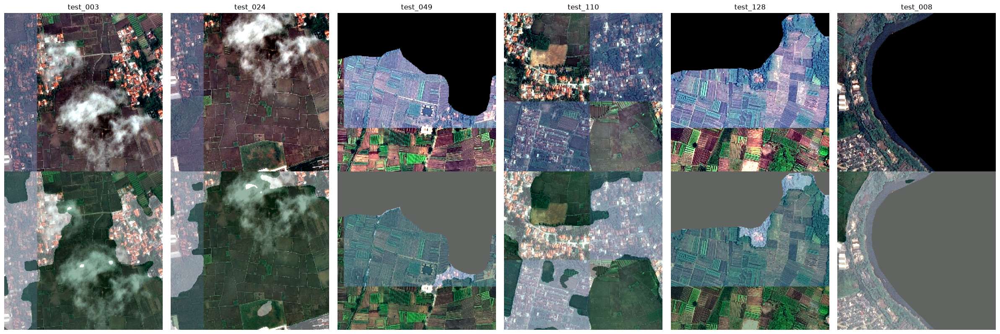

In [22]:
sub = pd.read_csv('submission.csv', keep_default_na=False)
assert list(sub.columns) == ['ImageId', 'EncodedPixels'] and len(sub) == 129
assert (sub.ImageId == sub_tmpl.ImageId).all()
print(sub.head())

test_prob = overlap_average(test_sum / n_models)
show = [3, 24, 49, 110, 128, 8]
fig, ax = plt.subplots(2, len(show), figsize=(4 * len(show), 8))
for c, i in enumerate(show):
    ax[0, c].imshow(X_test[i][::4, ::4])
    ax[0, c].set_title(sub_tmpl.ImageId[i])
    ax[1, c].imshow(X_test[i][::4, ::4])
    ax[1, c].imshow(postprocess(test_prob[i], NOD_TE[i], CFG.SUB_THR)[::4, ::4], alpha=.4, cmap='Greens')
    ax[0, c].axis('off')
    ax[1, c].axis('off')
plt.tight_layout()
plt.show()

---

## Submisi Final

Submisi final adalah *ensemble* v3 dan run 1 pada threshold 0.15 dengan aturan kosong 1%. Pilihan threshold berasal dari kurva threshold yang konsisten pada beberapa run (sisi tinggi curam, sisi rendah landai). Tile dengan prediksi sawah di bawah 1% luas tile dikosongkan karena blob sekecil itu hampir pasti *false positive* pada tile permukiman.

In [ ]:
def rle_decode(rle, shape=(1024, 1024)):
    m = np.zeros(shape[0] * shape[1], np.uint8)
    s = list(map(int, rle.split()))
    for a, l in zip(s[0::2], s[1::2]):
        m[a - 1:a - 1 + l] = 1
    return m.reshape(shape, order='F')

FINAL_THR, EMPTY_BELOW = 0.15, 0.01
final_prob = (test_sum / n_models + sum(others)) / (1 + len(others))
final_rows, emptied = [], []
for tid, p, nd in zip(sub_tmpl.ImageId, final_prob, NOD_TE):
    m = postprocess(p, nd, FINAL_THR)
    if 0 < m.mean() < EMPTY_BELOW:
        emptied.append(f'{tid} ({m.mean():.3%})')
        m[:] = False
    final_rows.append(rle_encode(m))
final_sub = pd.DataFrame({'ImageId': sub_tmpl.ImageId, 'EncodedPixels': final_rows})
assert list(final_sub.columns) == ['ImageId', 'EncodedPixels'] and len(final_sub) == 129
assert (final_sub.ImageId == sub_tmpl.ImageId).all()
final_path = CFG.OUTPUT_DIR / 'sub_final_ens2r_thr0.15_empty1.csv'
final_sub.to_csv(final_path, index=False)
final_sub.to_csv('submission.csv', index=False)
print(f'anggota ensemble: v3 ({n_models} fold) + {len(others)} run sebelumnya | threshold {FINAL_THR} | aturan kosong < {EMPTY_BELOW:.0%}')
print('tile yang dikosongkan:', emptied)
print(f'wrote {final_path} dan submission.csv | rows={len(final_sub)} | empty={(final_sub.EncodedPixels == "").sum()}')
ref_path = CFG.OUTPUT_DIR / 'sub_ens2r_thr0.15.csv'
if ref_path.exists():
    ref = pd.read_csv(ref_path, keep_default_na=False)
    px_diff = np.array([(rle_decode(a) != rle_decode(b)).mean() if (a or b) else 0.0 for a, b in zip(ref.EncodedPixels, final_sub.EncodedPixels)])
    print(f'cek terhadap {ref_path.name}: tile berbeda >0.1% piksel = {list(ref.ImageId[px_diff > 0.001])} | '
          f'selisih piksel median tile lain {np.median(px_diff[px_diff <= 0.001]):.2e}')

anggota ensemble: v3 (5 fold) + 1 run sebelumnya | threshold 0.15 | aturan kosong < 1%
tile yang dikosongkan: ['test_034 (0.602%)']
wrote outputs/dinov3_sat_v3/sub_final_ens2r_thr0.15_empty1.csv dan submission.csv | rows=129 | empty=1
cek terhadap sub_ens2r_thr0.15.csv: tile berbeda >0.1% piksel = ['test_034'] | selisih piksel median tile lain 9.54e-07


---

## Tile Validasi Tersulit

Lima tile validasi dengan IoU terendah ditampilkan sebagai peta kesalahan: hijau TP, merah FP, biru FN.

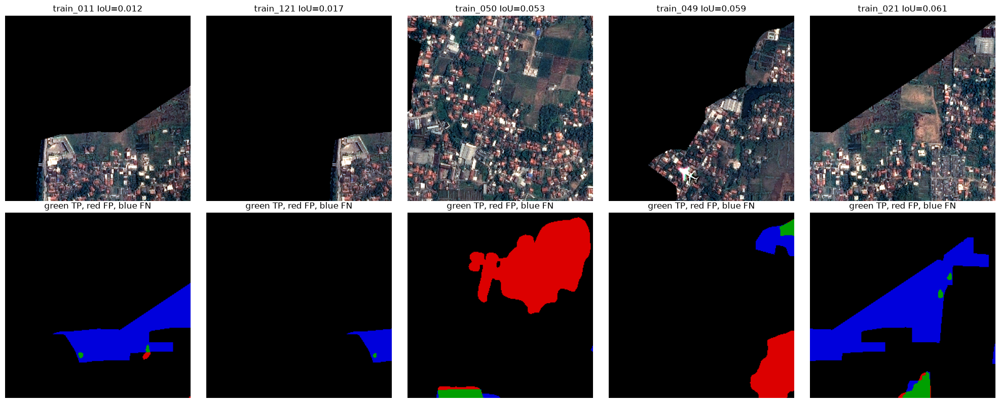

In [23]:
d = np.where(done)[0] if done.any() else np.array([0])
per_tile = [micro_iou(oof[i:i + 1], Y_train[i:i + 1], NOD_TR[i:i + 1], *best) for i in d]
worst = d[np.argsort(per_tile)[:5]]
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
for c, i in enumerate(worst):
    pr = postprocess(oof[i], NOD_TR[i], *best)
    err = np.zeros((1024, 1024, 3), np.uint8)
    err[pr & (Y_train[i] == 1)] = (0, 160, 0)
    err[pr & (Y_train[i] == 0)] = (220, 0, 0)
    err[~pr & (Y_train[i] == 1)] = (0, 0, 220)
    ax[0, c].imshow(X_train[i][::4, ::4])
    ax[0, c].set_title(f'{folds.id[i]} IoU={per_tile[list(d).index(i)]:.3f}')
    ax[1, c].imshow(err[::4, ::4])
    ax[1, c].set_title('green TP, red FP, blue FN')
    ax[0, c].axis('off')
    ax[1, c].axis('off')
plt.tight_layout()
plt.show()

> ### Insights
> Kesalahan terbesar berupa blok sepetak utuh pada tile permukiman dan petak bera, bukan garis batas. Hal ini konsisten dengan `eda/09`: 82% FP dan 89% FN berada pada blob minimal 4096 piksel, sehingga peningkatan berikutnya harus datang dari pemahaman semantik, bukan *refinement* tepi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

---

## Peta Ketidakpastian pada Test

Massa probabilitas di pita 0.1 sampai 0.5 menunjukkan di mana model ragu pada wilayah yang belum pernah dilihat. Lima tile test dengan pita ragu terbesar ditampilkan bersama peta probabilitasnya.

pita ragu 0.1<p<0.5: OOF 0.0329 | test 0.0545 | tile >5%: train 19/123, test 60/129


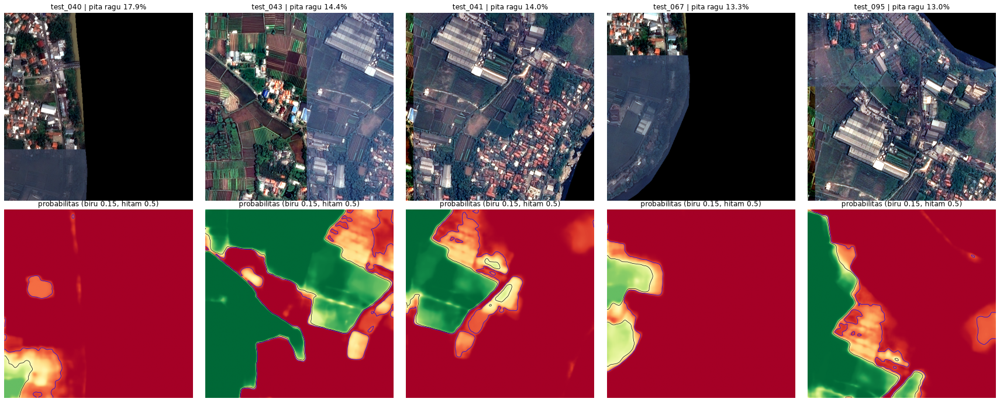

In [ ]:
own_prob = test_sum / n_models
band = np.array([(((p > 0.1) & (p < 0.5)) & ~nd).sum() / max((~nd).sum(), 1) for p, nd in zip(own_prob, NOD_TE)])
band_oof = np.array([(((p > 0.1) & (p < 0.5)) & ~nd).sum() / max((~nd).sum(), 1) for p, nd in zip(oof, NOD_TR)])
print(f'pita ragu 0.1<p<0.5: OOF {band_oof.mean():.4f} | test {band.mean():.4f} | tile >5%: train {(band_oof > .05).sum()}/123, test {(band > .05).sum()}/129')
top = np.argsort(band)[::-1][:5]
fig, ax = plt.subplots(2, 5, figsize=(24, 9.6))
for c, i in enumerate(top):
    ax[0, c].imshow(X_test[i][::2, ::2])
    ax[0, c].set_title(f'{sub_tmpl.ImageId[i]} | pita ragu {band[i]:.1%}')
    ax[1, c].imshow(own_prob[i][::2, ::2].astype(np.float32), cmap='RdYlGn', vmin=0, vmax=1)
    ax[1, c].contour(own_prob[i][::2, ::2].astype(np.float32), [0.15, 0.5], colors=['b', 'k'], linewidths=0.7)
    ax[1, c].set_title('probabilitas (biru 0.15, hitam 0.5)')
    ax[0, c].axis('off')
    ax[1, c].axis('off')
plt.tight_layout()
plt.show()

> ### Insights
> Keraguan terbesar muncul pada petak luas di sekitar kompleks bangunan besar dan pada tile mosaik dengan blok berkabut. Area tersebut adalah kombinasi tampilan yang jarang di train, sehingga model memberi probabilitas menengah alih-alih salah total. Itulah alasan threshold rendah membantu pada blok test.

---

## Estimasi Luas Sawah

Nilai guna model terletak pada estimasi luas tanam. Dengan asumsi GSD 0.5 m (Pleiades *pan-sharpened*), setiap piksel mewakili 0.25 m2 dan satu tile mewakili sekitar 26 ha.

luas satu tile: 26.2 ha (asumsi GSD 0.5 m, Pleiades pan-sharpened)
sawah per tile test: median 12.6 ha | total prediksi 1,526 ha (penjumlahan per tile, area overlap antar tile terhitung ganda)
sawah per tile train (GT): median 9.0 ha | proporsi sawah dari area valid test: 51.9%


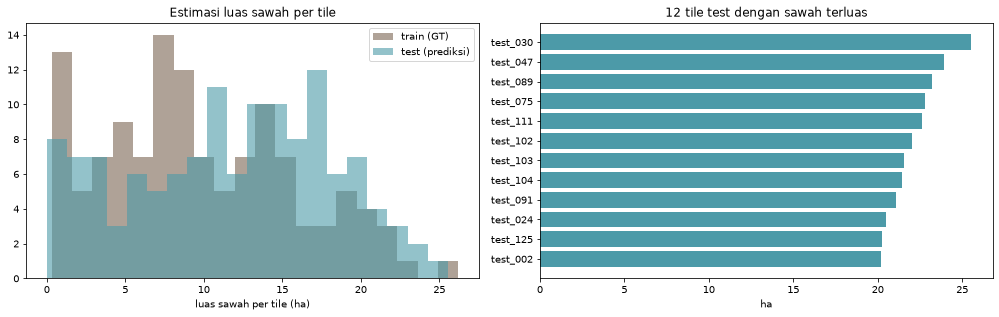

In [ ]:
GSD_M = 0.5
PX_HA = GSD_M ** 2 / 1e4
final_masks = [rle_decode(r) if r else np.zeros((1024, 1024), np.uint8) for r in final_sub.EncodedPixels]
area_te = np.array([m.sum() * PX_HA for m in final_masks])
area_tr = Y_train.reshape(len(Y_train), -1).sum(1) * PX_HA
valid_ha_te = np.array([(~nd).sum() * PX_HA for nd in NOD_TE])
print(f'luas satu tile: {1024 * 1024 * PX_HA:.1f} ha (asumsi GSD {GSD_M} m, Pleiades pan-sharpened)')
print(f'sawah per tile test: median {np.median(area_te):.1f} ha | total prediksi {area_te.sum():,.0f} ha (penjumlahan per tile, area overlap antar tile terhitung ganda)')
print(f'sawah per tile train (GT): median {np.median(area_tr):.1f} ha | proporsi sawah dari area valid test: {area_te.sum() / valid_ha_te.sum():.1%}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(area_tr, bins=20, alpha=0.7, label='train (GT)', color='#8E7B6B')
ax[0].hist(area_te, bins=20, alpha=0.6, label='test (prediksi)', color='#4C9AA8')
ax[0].set_xlabel('luas sawah per tile (ha)')
ax[0].set_title('Estimasi luas sawah per tile')
ax[0].legend()
top_area = np.argsort(area_te)[::-1][:12]
ax[1].barh([sub_tmpl.ImageId[i] for i in top_area][::-1], area_te[top_area][::-1], color='#4C9AA8')
ax[1].set_xlabel('ha')
ax[1].set_title('12 tile test dengan sawah terluas')
plt.tight_layout()
plt.show()

> ### Insights
> Masker final dapat langsung dikonversi menjadi luas sawah per tile untuk pemantauan alih fungsi lahan. Untuk total wilayah, area overlap antar tile perlu dihitung sekali menggunakan koordinat asli yang tidak tersedia pada data kompetisi.

### Kelebihan Pendekatan

Setiap keputusan *preprocessing* memiliki bukti angka dari data: *stretch* per tile, bank gain dari overlap nyata, haze regional, dan aturan NoData. Dua bug augmentasi yang tidak terlihat secara teori (haze no-op dan bintik hitam awan) ditemukan karena setiap augmentasi diukur, bukan hanya dilihat. Validasi spasial dengan *purge* menutup kebocoran dari tile overlap, dan pemilihan model berbasis OOF membuat hasil tidak bergantung pada 71 citra publik.

---

### Keterbatasan yang Diketahui

Pergeseran semantik ke blok test belum teratasi: pita ragu test masih 1.66 kali OOF. Validasi berupa pita Y di dalam strip train, sedangkan test berada pada blok X lain, sehingga OOF tetap lebih optimis daripada skor test. Tile bersawah sedikit (di bawah 15%) masih memiliki IoU rendah.

---

### Arah Pengembangan Berikutnya

Validasi yang meniru *split* X (pita X atau *buffer* lebih lebar), loss yang langsung mengoptimasi IoU (misalnya Lovasz), *backbone* kedua dengan bias berbeda untuk keragaman *ensemble*, dan TTA multi-skala. Untuk penerapan nyata, estimasi luas per desa dapat dihitung langsung bila koordinat tile tersedia.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Simeoni, O., Vo, H. V., Seitzer, M., Baldassarre, F., Oquab, M., Jose, C., Khalidov, V., Szafraniec, M., Yi, S., Ramamonjisoa, M., Massa, F., Haziza, D., Wehrstedt, L., Wang, J., Darcet, T., Moutakanni, T., Sentana, L., Roberts, C., Vedaldi, A., Tolan, J., Brandt, J., Couprie, C., Mairal, J., Jegou, H., Labatut, P., & Bojanowski, P. (2025). *DINOv3*. arXiv:2508.10104.

Darcet, T., Oquab, M., Mairal, J., & Bojanowski, P. (2024). *Vision Transformers Need Registers*. ICLR 2024. arXiv:2309.16588.

Ranftl, R., Bochkovskiy, A., & Koltun, V. (2021). *Vision Transformers for Dense Prediction*. ICCV 2021. arXiv:2103.13413.

Lin, T.-Y., Dollar, P., Girshick, R., He, K., Hariharan, B., & Belongie, S. (2017). *Feature Pyramid Networks for Object Detection*. CVPR 2017. arXiv:1612.03144.

Clark, K., Luong, M.-T., Le, Q. V., & Manning, C. D. (2020). *ELECTRA: Pre-training Text Encoders as Discriminators Rather Than Generators*. ICLR 2020 (*layer-wise learning rate decay*). arXiv:2003.10555.

Roberts, D. R., Bahn, V., Ciuti, S., dkk. (2017). *Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure*. Ecography, 40(8), 913-929.

Wolf, T., Debut, L., Sanh, V., dkk. (2020). *Transformers: State-of-the-Art Natural Language Processing*. EMNLP 2020. arXiv:1910.03771.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Terima Kasih <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih khusus kepada:**

Panitia **HOLOGY 9.0** dan penyusun kompetisi **[Holomine] Paddy Field Segmentation** yang telah menyediakan dataset dan platform kompetisi yang menantang.